# What My News Diet Leaves Out
**CS156 Pipeline Assignment 1.** Almira Halkina

This notebook contains the full pipeline behind the report. It compares the four Telegram channels I read (my feed) with a reference basket of 19 Russian-language channels and measures what my feed covers less, by topic, by place and by wording.

1. **Ingestion.** Collect public posts from 19 channels into an SQLite database.
2. **Preprocessing.** Filter, clean, deduplicate and lemmatise the posts.
3. **Features.** TF-IDF over lemmas and over character n-grams.
4. **Classifiers.** Tell my feed's posts from the basket's (Naive Bayes, logistic regression, linear SVM), with a temporal split, a leave-one-channel-out test and a tuned threshold.
5. **Topic models.** LDA and NMF, selected by coherence and stability; each channel becomes a distribution over topics.
6. **Metrics.** Echo score (Jensen–Shannon divergence from the basket), coverage gaps, an exhaustive null model, bootstrap, reading-weight sensitivity and blind-spot rates.
7. **Framing and geography.** Marker words, an attacker-naming rule, Fightin' Words, and named-entity recognition for places.
8. **Codebook labels.** Hand-defined categories as a check on the topic model.
9. **Interactive selector and dashboard export.**

**Data.** The corpus was collected on 8 and 13 October 2026: 40,580 posts from 19 channels. The analysis window is 1 September to 4 October 2026. The database and all slow intermediate results are stored on Google Drive, so the notebook runs from top to bottom without crawling or refitting.

**Running in Colab.** Run the cells in order. The first cell installs the Russian NLP packages, and the Drive cell restores the database.

## 0. Setup

In [4]:
# Colab does not keep installed packages between sessions
!pip install -q "pymorphy3>=2.0" "razdel>=0.5" "nltk>=3.8" "ipywidgets>=8.0"

In [5]:
# Standard library
import json
import math
import random
import re
import sqlite3
import time
import unicodedata
from collections import Counter
from datetime import datetime, timedelta, timezone
from functools import lru_cache
from itertools import combinations
from pathlib import Path

# Data handling, plotting and web scraping
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from bs4 import BeautifulSoup

# scikit-learn: features, models, validation and metrics
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, LeaveOneGroupOut,
                                     cross_val_predict, train_test_split)
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# One seed for every random step, so results are reproducible
RNG_SEED = 156
np.random.seed(RNG_SEED)
random.seed(RNG_SEED)

# Local paths (replaced by Colab paths in the next cell)
DB_PATH = Path("data/news.db")
DB_PATH.parent.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Collection window (UTC). Fixed so the corpus is reproducible.
WINDOW_START = datetime(2026, 9, 1, tzinfo=timezone.utc)
WINDOW_END = datetime(2026, 10, 5, tzinfo=timezone.utc)   # exclusive

### Storage on Google Drive (Colab)
SQLite is unreliable on a mounted Google Drive, so the notebook works on a local copy of the database and backs it up to Drive. The backup is written from a consistent snapshot and only after it passes SQLite's integrity check, so a damaged file can never overwrite a good backup. A dated copy is also kept for each day. Outside Colab this cell does nothing and the database stays in `data/`.

In [6]:
# Mount Google Drive, restore the database to local disk, and define integrity-checked backups
import os
import shutil

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/cs156-news-diet")
    LOCAL_DIR = Path("/content/work")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    (LOCAL_DIR / "data").mkdir(parents=True, exist_ok=True)
    (LOCAL_DIR / "figures").mkdir(exist_ok=True)
    os.chdir(LOCAL_DIR)
    DB_PATH = LOCAL_DIR / "data" / "news.db"
    FIG_DIR = LOCAL_DIR / "figures"

    backup = DRIVE_DIR / "news.db"
    if backup.exists():
        for suffix in ["", "-journal", "-wal", "-shm"]:      # remove stale local files first
            f = Path(str(DB_PATH) + suffix)
            if f.exists():
                f.unlink()
        shutil.copy(backup, DB_PATH)
        print(f"restored news.db from Drive ({backup.stat().st_size / 1e6:.1f} MB)")
    else:
        print("no backup in Drive yet; the crawl will start from scratch")


# Slow results (preprocessed posts, topic model) are cached here so a rerun after a disconnect is fast.
CACHE_DIR = DRIVE_DIR if IN_COLAB else Path("data")


def check_db(path):
    """Integrity check and post counts per channel, without modifying the file."""
    c = sqlite3.connect(f"file:{path}?mode=ro", uri=True)
    print("integrity:", c.execute("PRAGMA integrity_check").fetchone()[0])
    out = pd.read_sql("SELECT channel, COUNT(*) AS n_posts FROM posts GROUP BY channel ORDER BY channel", c)
    c.close()
    return out


def backup_db(conn):
    """Copy a consistent, integrity-checked snapshot of the database to Drive."""
    if not IN_COLAB:
        return
    snap = LOCAL_DIR / "snapshot.db"
    with sqlite3.connect(snap) as dst:
        conn.backup(dst)
    with sqlite3.connect(snap) as chk:
        ok = chk.execute("PRAGMA integrity_check").fetchone()[0] == "ok"
    if not ok:
        print("snapshot failed the integrity check; Drive backup NOT overwritten")
        return
    shutil.copy(snap, DRIVE_DIR / "news.db")
    shutil.copy(snap, DRIVE_DIR / f"news_{datetime.now():%Y%m%d}.db")
    print("backed up to Drive (integrity ok)")

Mounted at /content/drive
restored news.db from Drive (62.7 MB)


### Channel list
`group` is the label used by the classifiers: `diet` for the channels I read, `reference` for the rest of the basket. `category` describes the outlet and is only used to interpret results, never as a training label. My four channels are also part of the basket, so the basket average $p_R$ is taken over all 19 channels.

`weight` is my estimated share of reading time across my four channels. Because it is an estimate, Section 6 also reports every result with equal weights and with 2,000 random weightings.

In [7]:
# The 19 channels: my four (group = diet) and the reference basket, with outlet type and reading weight
CHANNELS = pd.DataFrame([
    # handle,          display name,             group,       category,                          weight
    ("nexta_live",     "NEXTA Live",             "diet",      "Belarusian independent (exile)",  0.35),
    ("Ateobreaking",   "Ateo Breaking",          "diet",      "aggregator",                      0.25),
    ("theinsider",     "The Insider",            "diet",      "Russian independent, investigative", 0.15),
    ("zerkalo_io",     "Zerkalo",                "diet",      "Belarusian independent (exile)",  0.25),
    ("rian_ru",        "RIA Novosti",            "reference", "Russian state",                    0.0),
    ("tass_agency",    "TASS",                   "reference", "Russian state",                    0.0),
    ("rbc_news",       "RBC",                    "reference", "Russian business",                 0.0),
    ("kommersant",     "Kommersant",             "reference", "Russian business",                 0.0),
    ("meduzalive",     "Meduza",                 "reference", "Russian independent (exile)",      0.0),
    ("tvrain",         "TV Rain",                "reference", "Russian independent (exile)",      0.0),
    ("novaya_europe",  "Novaya Gazeta Europe",   "reference", "Russian independent (exile)",      0.0),
    ("mediazzzona",    "Mediazona",              "reference", "Russian independent (exile)",      0.0),
    ("bbcrussian",     "BBC Russian",            "reference", "international public broadcaster", 0.0),
    ("currenttime",    "Current Time",           "reference", "international public broadcaster", 0.0),
    ("belta_telegramm","BelTA",                  "reference", "Belarusian state",                 0.0),
    ("pul_1",          "Pul Pervogo",            "reference", "Belarusian state",                 0.0),
    ("rybar",          "Rybar",                  "reference", "Russian pro-war military blog",    0.0),
    ("uniannet",       "UNIAN",                  "reference", "Ukrainian news agency, private",   0.0),
    ("stranaua",       "Strana.ua",              "reference", "Ukrainian general news, private",  0.0),
], columns=["handle", "name", "group", "category", "weight"])

assert abs(CHANNELS.loc[CHANNELS.group == "diet", "weight"].sum() - 1) < 1e-9
DIET = CHANNELS.loc[CHANNELS.group == "diet", "handle"].tolist()
ALL_CHANNELS = CHANNELS.handle.tolist()
CHANNELS

,handle,name,group,category,weight
0,nexta_live,NEXTA Live,diet,Belarusian independent (exile),0.35
1,Ateobreaking,Ateo Breaking,diet,aggregator,0.25
2,theinsider,The Insider,diet,"Russian independent, investigative",0.15
3,zerkalo_io,Zerkalo,diet,Belarusian independent (exile),0.25
4,rian_ru,RIA Novosti,reference,Russian state,0.00
5,tass_agency,TASS,reference,Russian state,0.00
6,rbc_news,RBC,reference,Russian business,0.00
7,kommersant,Kommersant,reference,Russian business,0.00
8,meduzalive,Meduza,reference,Russian independent (exile),0.00
9,tvrain,TV Rain,reference,Russian independent (exile),0.00


## 1. Ingestion

Public Telegram channels have a web preview at `https://t.me/s/<handle>`. Each request returns about 20 posts as HTML, newest last. Adding `?before=<post_id>` returns the 20 posts before that ID, so I can walk backwards through a channel until I pass `WINDOW_START`.

I chose the web preview over the Telegram API (Telethon) for two reasons: it needs no account credentials, and it shows what any reader sees. The cost is that I have to parse raw HTML. Each post is a `div.tgme_widget_message` with:

| Field | HTML source |
|---|---|
| post ID | `data-post="<handle>/<id>"` |
| timestamp (UTC) | `time[datetime]` inside `a.tgme_widget_message_date` |
| text | `div.tgme_widget_message_text.js-message_text` (`<br>` becomes a newline) |
| views | `span.tgme_widget_message_views` ("121K" is parsed as 121000) |
| forwarded from | `.tgme_widget_message_forwarded_from_name` |
| reply to | `a.tgme_widget_message_reply` href |
| media | photo, video, document, poll and unsupported-media containers |
| edited | "edited" in `.tgme_widget_message_meta` |

To keep the load on Telegram's servers low, the crawler waits 1.5–3 s between requests and backs off on HTTP 429. It also stores every page in SQLite as it goes, so an interrupted crawl resumes where it stopped.

In [8]:
# Crawler, part 1: download and parse one t.me/s preview page
BASE_URL = "https://t.me/s/{handle}"
HEADERS = {"User-Agent": "Mozilla/5.0 (research crawler for a university ML course; low rate)"}


def parse_count(s):
    """'121K' -> 121000, '1.2M' -> 1200000, '987' -> 987."""
    if not s:
        return None
    s = s.strip().upper().replace(",", ".")
    mult = 1
    if s.endswith("K"):
        mult, s = 1_000, s[:-1]
    elif s.endswith("M"):
        mult, s = 1_000_000, s[:-1]
    try:
        return int(float(s) * mult)
    except ValueError:
        return None


def html_to_text(node):
    """Text of a message node with <br> kept as line breaks."""
    if node is None:
        return ""
    for br in node.find_all("br"):
        br.replace_with("\n")
    return node.get_text().strip()


def parse_page(html, handle):
    """Parse one t.me/s page into a list of post dicts."""
    soup = BeautifulSoup(html, "html.parser")
    posts = []
    for msg in soup.select("div.tgme_widget_message[data-post]"):
        data_post = msg.get("data-post", "")
        try:
            post_id = int(data_post.split("/")[-1])
        except ValueError:
            continue
        if "service_message" in msg.get("class", []):
            continue

        time_tag = msg.select_one("a.tgme_widget_message_date time[datetime]")
        date_utc = None
        if time_tag:
            date_utc = datetime.fromisoformat(time_tag["datetime"]).astimezone(timezone.utc).isoformat()

        text_node = None
        for cand in msg.select("div.tgme_widget_message_text"):
            if cand.find_parent(class_="tgme_widget_message_reply") is None:
                text_node = cand
                break
        links = [a["href"] for a in text_node.select("a[href]")] if text_node else []
        text = html_to_text(text_node)

        fwd = msg.select_one(".tgme_widget_message_forwarded_from_name")
        reply = msg.select_one("a.tgme_widget_message_reply")
        reply_to = None
        if reply and reply.get("href"):
            m = re.search(r"/(\d+)(?:\?|$)", reply["href"])
            reply_to = int(m.group(1)) if m else None

        meta = msg.select_one(".tgme_widget_message_meta")
        views = msg.select_one("span.tgme_widget_message_views")

        posts.append({
            "channel": handle,
            "post_id": post_id,
            "date_utc": date_utc,
            "text": text,
            "views": parse_count(views.get_text()) if views else None,
            "forwarded_from": fwd.get_text(strip=True) if fwd else None,
            "reply_to": reply_to,
            "has_photo": int(msg.select_one(".tgme_widget_message_photo_wrap") is not None),
            "has_video": int(msg.select_one(".tgme_widget_message_video_player, .tgme_widget_message_roundvideo_player") is not None),
            "has_document": int(msg.select_one(".tgme_widget_message_document") is not None),
            "has_poll": int(msg.select_one(".tgme_widget_message_poll") is not None),
            "media_unsupported": int(msg.select_one(".message_media_not_supported") is not None),
            "edited": int(bool(meta and "edited" in meta.get_text())),
            "links": json.dumps(links, ensure_ascii=False),
        })
    return posts

### SQLite storage
One row per post, keyed on `(channel, post_id)`. `INSERT OR IGNORE` makes repeated crawls idempotent. The `pages` table logs every request, which documents how the data was collected.

In [9]:
# Crawler, part 2: SQLite storage, polite requests with retries, and backwards pagination
SCHEMA = """
CREATE TABLE IF NOT EXISTS posts (
    channel TEXT NOT NULL,
    post_id INTEGER NOT NULL,
    date_utc TEXT,
    text TEXT,
    views INTEGER,
    forwarded_from TEXT,
    reply_to INTEGER,
    has_photo INTEGER, has_video INTEGER, has_document INTEGER,
    has_poll INTEGER, media_unsupported INTEGER, edited INTEGER,
    links TEXT,
    source TEXT DEFAULT 'web_preview',
    scraped_at TEXT,
    PRIMARY KEY (channel, post_id)
);
CREATE TABLE IF NOT EXISTS pages (
    channel TEXT, before_id INTEGER, status INTEGER, n_posts INTEGER, fetched_at TEXT
);
CREATE INDEX IF NOT EXISTS idx_posts_date ON posts(date_utc);
"""


def get_conn(path=DB_PATH):
    """Open the database and create the tables if they do not exist."""
    conn = sqlite3.connect(path)
    conn.executescript(SCHEMA)
    return conn


def save_posts(conn, posts, source="web_preview"):
    """Insert parsed posts; INSERT OR IGNORE skips posts that are already stored."""
    now = datetime.now(timezone.utc).isoformat()
    rows = [(p["channel"], p["post_id"], p["date_utc"], p["text"], p["views"], p["forwarded_from"],
             p["reply_to"], p["has_photo"], p["has_video"], p["has_document"], p["has_poll"],
             p["media_unsupported"], p["edited"], p["links"], source, now) for p in posts]
    conn.executemany("INSERT OR IGNORE INTO posts VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)", rows)
    conn.commit()


def fetch_page(session, handle, before=None, max_retries=5):
    """GET one preview page. Retries on dropped connections and on HTTP 429 (rate limit)."""
    url = BASE_URL.format(handle=handle) + (f"?before={before}" if before else "")
    for attempt in range(max_retries):
        try:
            r = session.get(url, headers=HEADERS, timeout=30)
        except requests.ConnectionError:
            time.sleep(10 * (attempt + 1))
            continue
        if r.status_code == 429:
            time.sleep(int(r.headers.get("Retry-After", 30 * (attempt + 1))))
            continue
        return r
    return session.get(url, headers=HEADERS, timeout=30)


def crawl_channel(conn, handle, start=WINDOW_START, max_pages=2000, verbose=True):
    """Walk backwards through a channel until the window start.

    Pagination only follows posts dated inside or after the window, so a single old post on a
    page (a pinned post, for example) cannot end the crawl early. A rerun resumes from the
    oldest in-window post already stored.
    """
    session = requests.Session()
    s_iso = start.isoformat()
    edge = conn.execute("SELECT COUNT(*) FROM posts WHERE channel=? AND date_utc < ? AND date_utc >= ?",
                        (handle, s_iso, (start - timedelta(days=3)).isoformat())).fetchone()[0]
    if edge:
        if verbose:
            print(f"{handle}: already covers the window")
        return
    before = conn.execute("SELECT MIN(post_id) FROM posts WHERE channel=? AND date_utc >= ?",
                          (handle, s_iso)).fetchone()[0]
    for page in range(max_pages):
        r = fetch_page(session, handle, before)
        posts = parse_page(r.text, handle) if r.status_code == 200 else []
        conn.execute("INSERT INTO pages VALUES (?,?,?,?,?)",
                     (handle, before, r.status_code, len(posts), datetime.now(timezone.utc).isoformat()))
        conn.commit()
        if not posts:
            if verbose:
                print(f"{handle}: empty page (HTTP {r.status_code}) before post {before}; rerun later to resume")
            break
        save_posts(conn, posts)
        recent = [p for p in posts if p["date_utc"] and datetime.fromisoformat(p["date_utc"]) >= start]
        if not recent:
            break                                   # whole page is older than the window: done
        new_before = min(p["post_id"] for p in recent)
        if verbose and page % 25 == 0:
            oldest = min(datetime.fromisoformat(p["date_utc"]) for p in recent)
            print(f"{handle}: page {page}, oldest in window {oldest.date()}")
        if new_before == before or new_before <= 1:
            break
        before = new_before
        time.sleep(random.uniform(1.5, 3.0))
    conn.commit()

### Parser check
A minimal page with the same structure as a real `t.me/s` page: one normal post, one forward with a reply, and one service message. This confirms the parser before running the full crawl.

In [10]:
# Unit test for the parser on a hand-written page with a normal post, a forward/reply and a service message
FIXTURE = """
<div class="tgme_widget_message_wrap"><div class="tgme_widget_message" data-post="testchan/101">
  <div class="tgme_widget_message_text js-message_text">Первая строка<br/>Вторая строка <a href="https://example.org">ссылка</a></div>
  <a class="tgme_widget_message_photo_wrap"></a>
  <div class="tgme_widget_message_footer"><span class="tgme_widget_message_meta">
    <span class="tgme_widget_message_views">121K</span> edited
    <a class="tgme_widget_message_date" href="https://t.me/testchan/101"><time datetime="2026-09-14T16:12:00+00:00"></time></a></span></div>
</div></div>
<div class="tgme_widget_message_wrap"><div class="tgme_widget_message" data-post="testchan/102">
  <div class="tgme_widget_message_forwarded_from">Forwarded from <a class="tgme_widget_message_forwarded_from_name" href="https://t.me/other">Other</a></div>
  <a class="tgme_widget_message_reply" href="https://t.me/testchan/101"><div class="tgme_widget_message_text js-message_reply_text">Первая строка</div></a>
  <div class="tgme_widget_message_text js-message_text">Ответ на пост</div>
  <span class="tgme_widget_message_meta"><span class="tgme_widget_message_views">987</span>
  <a class="tgme_widget_message_date"><time datetime="2026-09-14T19:00:00+03:00"></time></a></span>
</div></div>
<div class="tgme_widget_message_wrap"><div class="tgme_widget_message service_message" data-post="testchan/103"></div></div>
"""
_parsed = parse_page(FIXTURE, "testchan")
assert len(_parsed) == 2
assert _parsed[0]["text"] == "Первая строка\nВторая строка ссылка"
assert _parsed[0]["views"] == 121000 and _parsed[0]["edited"] == 1 and _parsed[0]["has_photo"] == 1
assert _parsed[1]["forwarded_from"] == "Other" and _parsed[1]["reply_to"] == 101
assert _parsed[1]["text"] == "Ответ на пост"
assert _parsed[1]["date_utc"] == "2026-09-14T16:00:00+00:00"
pd.DataFrame(_parsed)[["post_id", "date_utc", "text", "views", "forwarded_from", "reply_to", "has_photo", "edited"]]

,post_id,date_utc,text,views,forwarded_from,reply_to,has_photo,edited
0,101,2026-09-14T16:12:00+00:00,Первая строка\nВторая строка ссылка,121000,None,NaN,1,1
1,102,2026-09-14T16:00:00+00:00,Ответ на пост,987,Other,101.0,0,0


### Run the crawl
The corpus is already collected, so `RUN_CRAWL` is off. With it on, channels that already cover the window are skipped and unfinished ones resume from their oldest stored post; the database is backed up to Drive after each channel. A full crawl from scratch is about 2,000 requests and takes 1.5–2 hours.

In [11]:
# Run the crawl (off: the corpus is already collected) and show posts per channel in the database
RUN_CRAWL = False

conn = get_conn(DB_PATH)
if RUN_CRAWL:
    for h in ALL_CHANNELS:
        try:
            crawl_channel(conn, h)
            backup_db(conn)
        except requests.RequestException as e:
            print(f"{h}: stopped ({e}); rerun to resume")

pd.read_sql("SELECT channel, COUNT(*) AS n_posts, MIN(date_utc) AS first, MAX(date_utc) AS last "
            "FROM posts GROUP BY channel ORDER BY n_posts DESC", conn)

,channel,n_posts,first,last
0,tass_agency,6145,2026-08-31T22:53:01+00:00,2026-10-08T14:25:21+00:00
1,belta_telegramm,5145,2026-08-31T20:34:59+00:00,2026-10-08T15:19:01+00:00
2,stranaua,3631,2026-08-31T18:35:01+00:00,2026-10-13T15:40:30+00:00
3,zerkalo_io,2927,2026-08-31T18:20:49+00:00,2026-10-08T14:15:40+00:00
4,uniannet,2647,2026-08-31T23:33:03+00:00,2026-10-08T15:34:56+00:00
5,kommersant,2452,2026-08-31T22:34:15+00:00,2026-10-08T14:47:57+00:00
6,rbc_news,2314,2026-08-31T15:56:17+00:00,2026-10-08T14:30:18+00:00
7,rian_ru,2238,2026-08-31T18:49:47+00:00,2026-10-08T13:52:22+00:00
8,Ateobreaking,2114,2026-08-31T16:10:26+00:00,2026-10-08T14:05:02+00:00
9,tvrain,1775,2026-08-31T18:00:35+00:00,2026-10-08T15:01:52+00:00


## 2. Preprocessing

The steps run in this order, and the notebook records how many posts each one removes:

1. **Window.** Keep posts inside `[WINDOW_START, WINDOW_END)`.
2. **Empty posts.** Media-only posts (no caption) are dropped.
3. **Language.** Tag each post as Russian, Ukrainian, Belarusian or other. All three languages use Cyrillic, so the tag comes from letters Russian does not have: ї, є and ґ are Ukrainian only, ў is Belarusian only, і is shared. Only Russian posts are kept.
4. **Boilerplate.** Each channel repeats its own lines, such as "Подписаться на NEXTA" (Subscribe to NEXTA) or a link to its website. Any line that recurs in at least 2% of a channel's posts (minimum 5 posts) is treated as that channel's boilerplate and removed.
5. **Outlet identifiers** (stripped version only): outlet names, @handles, hashtags, URLs and emoji. These features identify a channel trivially, so comparing raw and stripped text shows how much a classifier relies on them.
6. **Short posts.** Drop posts with fewer than `MIN_TOKENS` (8) content lemmas after cleaning. Many channels post a one-line headline plus a link, so a stricter threshold would remove most of their output (a threshold of 15 removes 78% of Zerkalo's posts).
7. **Near-duplicates.** Compare posts published within two days of each other by the cosine similarity of their TF-IDF vectors; pairs at or above 0.9 count as duplicates. A duplicate within one channel is dropped. A duplicate across channels (forwards, shared agency copy) is kept but flagged, because it is real overlap between outlets.
8. **Tokenise, lemmatise, remove stopwords.** razdel for tokenisation, pymorphy3 for lemmas (dictionary forms). Russian is heavily inflected (санкции, санкций, санкциями are three forms of "sanctions"), so without lemmatisation one concept would be split into many features.

**Cache.** Slow steps save their results to the Drive folder the first time they run: the preprocessed posts (`processed_v1.pkl`), the classifier comparisons (`model_a_*`), the topic models (`lda_v1.joblib`, `topic_selection_v1.joblib`, `topic_final_*`) and the place names (`locations_v1.pkl`). A rerun loads them instead of recomputing. Everything downstream of preprocessing is only reused while `processed_v1.pkl` is; deleting it recomputes everything.

In [13]:
# Load the cached preprocessed posts if they exist; otherwise the cells below recompute them
PROCESSED_CACHE = CACHE_DIR / "processed_v1.pkl"
CACHED = PROCESSED_CACHE.exists()
if CACHED:
    df, log = pd.read_pickle(PROCESSED_CACHE)
    print(f"loaded {len(df):,} preprocessed posts from {PROCESSED_CACHE}")

loaded 32,376 preprocessed posts from /content/drive/MyDrive/cs156-news-diet/processed_v1.pkl


In [14]:
# Steps 1-2: load posts, keep the time window, drop media-only posts
if not CACHED:
    df_raw = pd.read_sql("SELECT * FROM posts", conn, parse_dates=["date_utc"])
    df_raw["date_utc"] = pd.to_datetime(df_raw["date_utc"], utc=True)
    df_raw = df_raw[df_raw.channel.isin(ALL_CHANNELS)].copy()     # drops channels removed from the basket
    log = [("collected", len(df_raw))]

    df = df_raw[(df_raw.date_utc >= WINDOW_START) & (df_raw.date_utc < WINDOW_END)].copy()
    log.append(("inside window", len(df)))

    df["text"] = df["text"].fillna("")
    media_only = (df.text.str.strip() == "")
    df = df[~media_only].copy()
    log.append(("has text", len(df)))

In [15]:
# Step 3: language tag from letters that Russian does not use
if not CACHED:
    UK_ONLY, BE_ONLY, SHARED = set("їєґЇЄҐ"), set("ўЎ"), set("іІ")


    def detect_lang(text, max_foreign_share=0.02, min_cyr_share=0.6):
        """'ru', 'uk', 'be' or 'other', from the letters Russian does not use."""
        letters = [c for c in text if c.isalpha()]
        if len(letters) < 20:
            return "other"
        cyr = sum("\u0400" <= c <= "\u04FF" for c in letters)
        if cyr / len(letters) < min_cyr_share:
            return "other"
        uk, be, shared = (sum(c in group for c in letters) for group in (UK_ONLY, BE_ONLY, SHARED))
        if (uk + be + shared) / len(letters) <= max_foreign_share:
            return "ru"
        return "be" if be > uk else "uk"


    df["lang"] = df.text.map(detect_lang)
    lang_table = pd.crosstab(df.channel, df.lang)
    display(lang_table)

In [16]:
# Keep Russian-language posts only
if not CACHED:
    df = df[df.lang == "ru"].copy()
    log.append(("Russian", len(df)))
    assert len(df) > 0, f"no posts left after filtering: {log}"

In [17]:
# Steps 4-5: boilerplate removal and outlet-identifier stripping
if not CACHED:
    # Patterns for URLs, mentions, hashtags and emoji
    URL_RE = re.compile(r"https?://\S+|www\.\S+|t\.me/\S+")
    MENTION_RE = re.compile(r"@\w+")
    HASHTAG_RE = re.compile(r"#\w+")
    EMOJI_RE = re.compile("[\U0001F000-\U0001FAFF☀-➿️‍⬀-⯿]+")

    # Outlet names in Cyrillic and Latin script, allowing for Russian inflection
    OUTLET_PATTERNS = [
        r"NEXTA|Некст\w*", r"Ateo\w*|Атео\w*", r"The Insider|Инсайдер\w*", r"Zerkalo|Зеркал[оа]\b|«Зеркал\w*»",
        r"РИА\s*Новост\w*|РИА\b|RIA", r"ТАСС|TASS", r"РБК|RBC", r"Коммерсант\w*|\bЪ\b",
        r"Медуз\w*|Meduza", r"«Дожд\w*»|телеканал\w*\s+Дожд\w*|TV Rain", r"Новая\s+газета(?:\s+Европа)?|Новой\s+газет\w*",
        r"Медиазон\w*|Mediazona", r"Би-би-си|BBC|Русская служба", r"Настоящее\s+[Вв]рем\w*|Current Time",
        r"Б[Ее]Л[Тт][Аа]|BelTA|БелТА", r"Пул\w*\s+Перв\w*", r"Рыбар\w*|Rybar",
        r"УНИАН\w*|UNIAN", r"Strana\.ua|Strana|«Стран[аы]»|Страна\.ua",
    ]
    OUTLET_RE = re.compile("|".join(f"(?:{p})" for p in OUTLET_PATTERNS))
    # Latin-script outlet names, in any capitalization ("insider", "Meduza", "TASS")
    LATIN_OUTLET_RE = re.compile(r"\b(?:nexta|ateo\w*|the\s+insider|insider|zerkalo|ria|tass|rbc|meduza|tv\s*rain|"
                                 r"novaya\s+gazeta|mediazona|bbc|current\s+time|belta|rybar|unian|strana(?:\.ua)?)\b",
                                 re.IGNORECASE)


    # Step 4: per-channel boilerplate lines (recurring in >= 2% of a channel's posts)
    def norm_line(line):
        line = URL_RE.sub(" URL ", line.lower())
        line = re.sub(r"\d+", "0", line)
        return re.sub(r"\s+", " ", line).strip()


    def learn_boilerplate(frame, min_share=0.02, min_count=5):
        """Per-channel set of normalized lines that recur too often to be content."""
        boiler = {}
        for ch, texts in frame.groupby("channel")["text"]:
            counts = Counter()
            for t in texts:
                counts.update({norm_line(l) for l in t.split("\n") if l.strip()})
            thresh = max(min_count, min_share * len(texts))
            boiler[ch] = {l for l, c in counts.items() if c >= thresh and len(l) > 0}
        return boiler


    BOILERPLATE = learn_boilerplate(df)


    def remove_boilerplate(text, channel):
        keep = [l for l in text.split("\n") if norm_line(l) not in BOILERPLATE.get(channel, set())]
        return "\n".join(keep)


    # Step 5: two text versions, raw (names kept) and stripped (outlet identifiers removed)
    def clean_basic(text):
        text = unicodedata.normalize("NFC", text)
        text = URL_RE.sub(" ", text)
        return re.sub(r"\s+", " ", text).strip()


    def clean_stripped(text):
        text = OUTLET_RE.sub(" ", text)
        text = LATIN_OUTLET_RE.sub(" ", text)
        text = MENTION_RE.sub(" ", text)
        text = HASHTAG_RE.sub(" ", text)
        text = EMOJI_RE.sub(" ", text)
        return clean_basic(text)


    df["text_noboiler"] = [remove_boilerplate(t, c) for t, c in zip(df.text, df.channel)]
    df["text_raw"] = df["text"].map(clean_basic)
    df["text_stripped"] = df["text_noboiler"].map(clean_stripped)

    display(pd.DataFrame([(ch, len(lines), list(lines)[:3]) for ch, lines in BOILERPLATE.items()],
                 columns=["channel", "n_boilerplate_lines", "examples"]))

In [18]:
# Steps 6 and 8: tokenisation, lemmatisation and stopwords; length filter
if not CACHED:
    import pymorphy3
    from razdel import tokenize as razdel_tokenize

    MORPH = pymorphy3.MorphAnalyzer()

    # Russian stopwords from NLTK, with a fallback list if the download fails

    try:
        import nltk
        nltk.download("stopwords", quiet=True)
        from nltk.corpus import stopwords
        RU_STOP = set(stopwords.words("russian"))
    except Exception:
        RU_STOP = set("""и в во не что он на я с со как а то все она так его но да ты к у же вы за бы по только ее мне
        было вот от меня еще нет о из ему теперь когда даже ну вдруг ли если уже или ни быть был него до вас нибудь опять
        уж вам ведь там потом себя ничего ей может они тут где есть надо ней для мы тебя их чем была сам чтоб без будто
        чего раз тоже себе под будет ж тогда кто этот того потому этого какой совсем ним здесь этом один почти мой тем
        чтобы нее сейчас были куда зачем всех никогда можно при наконец два об другой хоть после над больше тот через
        эти нас про всего них какая много разве три эту моя впрочем хорошо свою этой перед иногда лучше чуть том нельзя
        такой им более всегда конечно всю между""".split())
    RU_STOP |= {"это", "весь", "который", "свой", "также", "наш", "ваш", "url"}


    # Lemma of one word; cached because the same words recur many times
    @lru_cache(maxsize=300_000)
    def lemma(word):
        return MORPH.parse(word)[0].normal_form.replace("ё", "е")


    def lemmatize(text):
        # "ё" is written by some channels and not others ("её" vs "ее"), so it is normalized to "е"
        text = text.replace("ё", "е").replace("Ё", "Е")
        toks = (t.text.lower() for t in razdel_tokenize(text))
        lemmas = [lemma(t) for t in toks if t.isalpha() and len(t) > 1]
        return " ".join(l for l in lemmas if l not in RU_STOP)


    df["lem_raw"] = df["text_raw"].map(lemmatize)
    df["lem_stripped"] = df["text_stripped"].map(lemmatize)
    df["n_tokens"] = df["lem_stripped"].map(lambda s: len(s.split()) if isinstance(s, str) else 0)
    # Step 6: minimum post length, with the effect of three thresholds per channel
    MIN_TOKENS = 8
    print("posts kept per channel at different length thresholds:")
    print(pd.DataFrame({f">= {m} lemmas": df[df.n_tokens >= m].groupby("channel").size() for m in (1, 8, 15)}).fillna(0).astype(int))
    df = df[df.n_tokens >= MIN_TOKENS].copy()
    log.append((f">= {MIN_TOKENS} lemmas", len(df)))

In [19]:
# Step 7: near-duplicates, compared within a two-day window by cosine similarity of TF-IDF vectors
if not CACHED:
    def flag_near_duplicates(frame, text_col="lem_stripped", threshold=0.9, window_days=2):
        """Return (within-channel duplicate mask, cross-channel duplicate mask)."""
        frame = frame.sort_values("date_utc").reset_index()
        X = TfidfVectorizer(min_df=1, sublinear_tf=True).fit_transform(frame[text_col])
        days = (frame.date_utc - frame.date_utc.min()).dt.days.to_numpy()
        within, cross = np.zeros(len(frame), bool), np.zeros(len(frame), bool)
        for d in np.unique(days):
            i_idx = np.where(days == d)[0]
            j_idx = np.where((days >= d) & (days < d + window_days))[0]
            sims = (X[i_idx] @ X[j_idx].T).tocoo()
            for a, b, s in zip(sims.row, sims.col, sims.data):
                i, j = i_idx[a], j_idx[b]
                if j <= i or s < threshold:
                    continue
                if frame.channel[i] == frame.channel[j]:
                    within[j] = True          # keep the earlier post
                else:
                    cross[i] = cross[j] = True
        return pd.Series(within, index=frame["index"]), pd.Series(cross, index=frame["index"])


    _within, _cross = flag_near_duplicates(df)
    df["xdup"] = _cross.reindex(df.index).to_numpy()
    df = df[~_within.reindex(df.index).to_numpy()].copy()
    log.append(("after within-channel dedup", len(df)))

    # Label for the classifiers: 1 if the post comes from one of my four channels
    df["y"] = df.channel.isin(DIET).astype(int)
    df = df.sort_values("date_utc").reset_index(drop=True)

In [20]:
# Save the preprocessed posts to Drive and show how many posts each step left
if not CACHED:
    pd.to_pickle((df, log), PROCESSED_CACHE)
    print(f"saved preprocessed posts to {PROCESSED_CACHE}")
pd.DataFrame(log, columns=["step", "posts remaining"]).replace({"Russian (incl. translated)": "Russian"})

,step,posts remaining
0,collected,40580
1,inside window,35829
2,has text,35426
3,Russian (incl. translated),35308
4,>= 8 lemmas,32581
5,after within-channel dedup,32376


### Corpus description
Posts per channel per day. Channels publish at very different rates, so later steps weight every channel equally when they compute channel averages.

In [21]:
# Corpus description per channel: posts, median length, share of forwards and of cross-channel duplicates
summary = (df.groupby("channel")
             .agg(posts=("post_id", "size"), median_tokens=("n_tokens", "median"),
                  share_forwarded=("forwarded_from", lambda s: s.notna().mean()),
                  share_xdup=("xdup", "mean"))
             .join(CHANNELS.set_index("handle")[["group", "category"]])
             .sort_values("posts", ascending=False))
summary

,posts,median_tokens,share_forwarded,share_xdup,group,category
channel,,,,,,
tass_agency,5352,17.0,0.002616,0.036622,reference,Russian state
belta_telegramm,3181,10.0,0.043383,0.055014,reference,Belarusian state
stranaua,2506,36.0,0.000000,0.013168,reference,"Ukrainian general news, private"
uniannet,2100,37.0,0.010952,0.012381,reference,"Ukrainian news agency, private"
zerkalo_io,2099,11.0,0.000476,0.001429,diet,Belarusian independent (exile)
kommersant,2093,44.0,0.103679,0.053512,reference,Russian business
rbc_news,1931,54.0,0.043501,0.013982,reference,Russian business
rian_ru,1857,21.0,0.000539,0.023694,reference,Russian state
Ateobreaking,1745,17.0,0.001146,0.075645,diet,aggregator


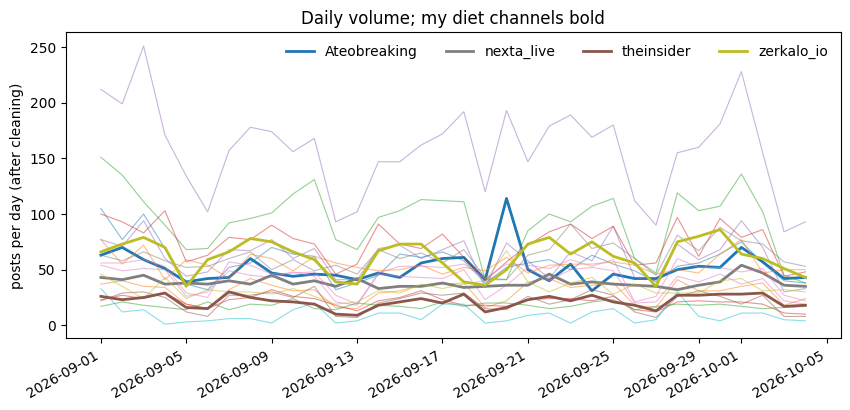

In [22]:
# Figure: posts per day per channel (my four channels drawn with thick lines)
daily = df.groupby([df.date_utc.dt.date, "channel"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4.5))
for ch in daily.columns:
    ax.plot(daily.index, daily[ch], lw=2 if ch in DIET else 0.8,
            alpha=1 if ch in DIET else 0.5, label=ch if ch in DIET else None)
ax.set_ylabel("posts per day (after cleaning)")
ax.set_title("Daily volume; my diet channels bold")
ax.legend(frameon=False, ncol=4)
fig.autofmt_xdate()
fig.savefig(FIG_DIR / "fig1_daily_volume.png", dpi=150, bbox_inches="tight")

## 3. Features

Each post becomes a TF-IDF vector over lemmas:

$$\text{tfidf}(t,d) = \big(1+\log \text{tf}(t,d)\big)\cdot \left(\log\frac{1+N}{1+\text{df}(t)} + 1\right)$$

with sublinear term frequency and L2 normalisation, so long posts do not dominate. Terms must occur in at least 5 posts and in at most half of them. The vectoriser is fitted on training data only.

In [23]:
def make_vectorizer(ngram=(1, 1)):
    """TF-IDF over lemmas: terms in at least 5 posts and at most half of them, sublinear term frequency."""
    return TfidfVectorizer(ngram_range=ngram, min_df=5, max_df=0.5, sublinear_tf=True)

## 4. Model A: my diet vs. the reference basket

Labels: $y_i = 1$ if post $i$ comes from a channel I follow, $0$ otherwise. The models estimate $P(y=1 \mid x_i)$.

- **Dummy** (most-frequent class): what accuracy looks like without reading the text.
- **Multinomial Naive Bayes**: generative; models $P(x \mid y)P(y)$ and assumes words are conditionally independent given the class.
- **Logistic regression**: discriminative; models $P(y \mid x)$ directly as a linear boundary in TF-IDF space.

Hyperparameters (NB `alpha`, LR `C`) are chosen by 3-fold cross-validation inside the training set only.

**Splits.** *Temporal*: posts from the first 75% of the window train the model and the last 25% test it, so the test set contains news events the model has not seen. *Random*: a stratified 75/25 split, for comparison. The gap between the two estimates how much performance comes from recognizing specific stories rather than how a diet reads in general.

In [24]:
# Temporal split: the first 75% of the window (by post time) trains, the last 25% tests
cutoff = df.date_utc.quantile(0.75)


def get_split(kind):
    """Train and test indices for the temporal or the random (stratified 75/25) split."""
    if kind == "temporal":
        tr = df.index[df.date_utc < cutoff]
        te = df.index[df.date_utc >= cutoff]
    else:
        tr, te = train_test_split(df.index, test_size=0.25, stratify=df.y, random_state=RNG_SEED)
    return tr, te


def make_model(name, ngram):
    """Classifier pipeline; hyperparameters are tuned by 3-fold CV on macro-F1 inside the training set."""
    if name == "dummy":
        return Pipeline([("tfidf", make_vectorizer(ngram)), ("clf", DummyClassifier(strategy="most_frequent"))])
    if name == "nb":
        pipe = Pipeline([("tfidf", make_vectorizer(ngram)), ("clf", MultinomialNB())])
        return GridSearchCV(pipe, {"clf__alpha": [0.1, 0.3, 1.0]}, cv=3, scoring="f1_macro", n_jobs=-1)
    if name == "lr":
        pipe = Pipeline([("tfidf", make_vectorizer(ngram)),
                         ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))])
        return GridSearchCV(pipe, {"clf__C": [0.3, 1.0, 3.0, 10.0]}, cv=3, scoring="f1_macro", n_jobs=-1)
    raise ValueError(name)


def evaluate(model_name, text_col="lem_stripped", ngram=(1, 1), split="temporal"):
    """Fit one condition on the training split and score it on the test split."""
    tr, te = get_split(split)
    model = make_model(model_name, ngram).fit(df.loc[tr, text_col], df.loc[tr, "y"])
    proba = model.predict_proba(df.loc[te, text_col])[:, 1]
    pred = (proba >= 0.5).astype(int)
    y_te = df.loc[te, "y"]
    return model, {
        "model": model_name, "text": text_col, "ngram": f"{ngram[0]}-{ngram[1]}", "split": split,
        "accuracy": accuracy_score(y_te, pred),
        "macro_F1": f1_score(y_te, pred, average="macro"),
        "ROC_AUC": roc_auc_score(y_te, proba) if model_name != "dummy" else 0.5,
    }

### Comparison conditions
Each row changes one thing relative to the baseline (stripped text, unigrams, temporal split).

In [25]:
# Each condition changes one setting relative to the baseline (logistic regression, stripped lemmas, unigrams, temporal split)
CONDITIONS = [
    dict(model_name="dummy"),
    dict(model_name="nb"),
    dict(model_name="lr"),
    dict(model_name="lr", split="random"),
    dict(model_name="nb", split="random"),
    dict(model_name="lr", text_col="lem_raw"),
    dict(model_name="lr", ngram=(1, 2)),
    dict(model_name="nb", ngram=(1, 2)),
]
import joblib

MODEL_A_CACHE = CACHE_DIR / "model_a_conditions_v1.joblib"   # fitted models and scores, saved after the first run
if MODEL_A_CACHE.exists() and CACHED:
    fitted, rows = joblib.load(MODEL_A_CACHE)
    print(f"loaded comparison conditions from {MODEL_A_CACHE}")
else:
    fitted, rows = {}, []
    for cond in CONDITIONS:
        model, res = evaluate(**cond)
        fitted[tuple(sorted(cond.items()))] = model
        rows.append(res)
    joblib.dump((fitted, rows), MODEL_A_CACHE)
results = pd.DataFrame(rows)
results.round(3)

loaded comparison conditions from /content/drive/MyDrive/cs156-news-diet/model_a_conditions_v1.joblib


,model,text,ngram,split,accuracy,macro_F1,ROC_AUC
0,dummy,lem_stripped,1-1,temporal,0.807,0.446,0.500
1,nb,lem_stripped,1-1,temporal,0.827,0.586,0.791
2,lr,lem_stripped,1-1,temporal,0.780,0.694,0.821
3,lr,lem_stripped,1-1,random,0.804,0.715,0.841
4,nb,lem_stripped,1-1,random,0.840,0.602,0.797
5,lr,lem_raw,1-1,temporal,0.877,0.814,0.935
6,lr,lem_stripped,1-2,temporal,0.813,0.718,0.838
7,nb,lem_stripped,1-2,temporal,0.831,0.603,0.809


### Leave one channel out
Each fold trains on 18 channels and scores the held-out one. Pooling the out-of-fold probabilities gives one ROC-AUC. If it stays well above 0.5, the model has learned what my feed covers in general rather than the writing style of four specific channels.

In [26]:
# Leave-one-channel-out: train on 18 channels, score the held-out one, pool the out-of-fold probabilities
logo = LeaveOneGroupOut()
lr_pipe = Pipeline([("tfidf", make_vectorizer()), ("clf", LogisticRegression(class_weight="balanced", C=1.0, max_iter=3000))])
HOLDOUT_CACHE = CACHE_DIR / "model_a_holdout_v1.npy"
if HOLDOUT_CACHE.exists() and CACHED:
    oof_holdout = np.load(HOLDOUT_CACHE)
else:
    oof_holdout = cross_val_predict(lr_pipe, df.lem_stripped, df.y, groups=df.channel, cv=logo,
                                    method="predict_proba", n_jobs=-1)[:, 1]
    np.save(HOLDOUT_CACHE, oof_holdout)
print("leave-one-channel-out ROC-AUC:", round(roc_auc_score(df.y, oof_holdout), 3))
df.assign(p=oof_holdout).groupby("channel").p.mean().sort_values().round(3)

leave-one-channel-out ROC-AUC: 0.503


,p
channel,
rbc_news,0.260
theinsider,0.268
kommersant,0.306
pul_1,0.310
rybar,0.314
tvrain,0.323
novaya_europe,0.350
stranaua,0.361
bbcrussian,0.374


### Final model: confusion matrix and learned vocabulary

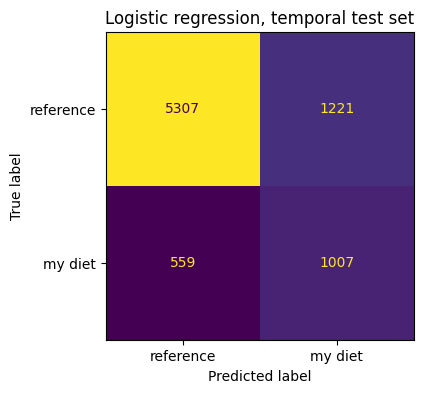

In [27]:
# Confusion matrix of the tuned logistic regression on the temporal test set
best = fitted[tuple(sorted(dict(model_name="lr").items()))]
tr, te = get_split("temporal")
pred = best.predict(df.loc[te, "lem_stripped"])
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(df.loc[te, "y"], pred),
                       display_labels=["reference", "my diet"]).plot(ax=ax, colorbar=False)
ax.set_title("Logistic regression, temporal test set")
fig.savefig(FIG_DIR / "fig2_confusion.png", dpi=150, bbox_inches="tight")

In [28]:
# Largest logistic-regression coefficients toward the basket and toward my feed
pipe = best.best_estimator_
vocab = np.array(pipe.named_steps["tfidf"].get_feature_names_out())
coef = pipe.named_steps["clf"].coef_[0]
order = np.argsort(coef)
top = pd.DataFrame({"toward reference": vocab[order[:20]], "coef_ref": coef[order[:20]].round(2),
                    "toward my diet": vocab[order[::-1][:20]], "coef_diet": coef[order[::-1][:20]].round(2)})
top

,toward reference,coef_ref,toward my diet,coef_diet
0,сообщить,-8.54,беларусский,8.60
1,отметить,-7.81,здравствуйте,6.64
2,читать,-7.59,беларуска,6.41
3,добавить,-6.80,беларус,5.82
4,всу,-6.65,беларусый,5.47
5,белорусский,-6.13,afd,5.14
6,фото,-6.04,беларусов,5.04
7,паблик,-6.00,threads,4.84
8,напомнить,-5.75,тихановский,4.46
9,корреспондент,-5.71,российский,4.18


### More models, a tuned threshold, and where the errors fall

Three additions to the comparison above:

- **Complement Naive Bayes** (Rennie et al., 2003): estimates each class's word weights from the *other* class's documents, which makes it more robust than multinomial NB when classes are imbalanced.
- **Linear SVM**: a maximum-margin linear boundary in the same TF-IDF space, with probabilities from Platt scaling (`CalibratedClassifierCV`).
- **Character n-grams** (2–5 characters within word boundaries) on the stripped text, without lemmatization. They capture word endings and spelling, which matters in a heavily inflected language.

**Decision threshold.** All models above predict "my feed" when $\hat P > 0.5$. With 19% positives, that cut-off is not where macro-F1 peaks. The threshold is tuned on a validation slice (the last 20% of the training period) and then applied once to the test set.

In [29]:
# Additional classifiers, fitted on the temporal split and added to the comparison table
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV


def make_model_extra(name):
    """Complement NB, linear SVM with Platt scaling, and logistic regression on character 2-5-grams."""
    if name == "cnb":
        pipe = Pipeline([("tfidf", make_vectorizer()), ("clf", ComplementNB())])
        return GridSearchCV(pipe, {"clf__alpha": [0.1, 0.3, 1.0]}, cv=3, scoring="f1_macro", n_jobs=-1)
    if name == "svm":
        return Pipeline([("tfidf", make_vectorizer()),
                         ("clf", CalibratedClassifierCV(LinearSVC(C=0.5, class_weight="balanced"), cv=3))])
    if name == "lr_char":
        return Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=5,
                                                   max_features=200_000, sublinear_tf=True)),
                         ("clf", LogisticRegression(class_weight="balanced", C=3.0, max_iter=3000))])
    raise ValueError(name)


EXTRA = [("cnb", "lem_stripped"), ("svm", "lem_stripped"), ("lr_char", "text_stripped")]
EXTRA_CACHE = CACHE_DIR / "model_a_extra_v1.joblib"
if EXTRA_CACHE.exists() and CACHED:
    extra_models, extra_rows = joblib.load(EXTRA_CACHE)
    print(f"loaded extra models from {EXTRA_CACHE}")
else:
    tr, te = get_split("temporal")
    extra_models, extra_rows = {}, []
    for name, col in EXTRA:
        m = make_model_extra(name).fit(df.loc[tr, col], df.loc[tr, "y"])
        proba = m.predict_proba(df.loc[te, col])[:, 1]
        pred = (proba >= 0.5).astype(int)
        extra_models[name] = m
        extra_rows.append({"model": name, "text": col, "ngram": "char 2-5" if name == "lr_char" else "1-1",
                           "split": "temporal", "accuracy": accuracy_score(df.loc[te, "y"], pred),
                           "macro_F1": f1_score(df.loc[te, "y"], pred, average="macro"),
                           "ROC_AUC": roc_auc_score(df.loc[te, "y"], proba)})
    joblib.dump((extra_models, extra_rows), EXTRA_CACHE)

all_results = pd.concat([results, pd.DataFrame(extra_rows)], ignore_index=True)
all_results.round(3)

loaded extra models from /content/drive/MyDrive/cs156-news-diet/model_a_extra_v1.joblib


,model,text,ngram,split,accuracy,macro_F1,ROC_AUC
0,dummy,lem_stripped,1-1,temporal,0.807,0.446,0.500
1,nb,lem_stripped,1-1,temporal,0.827,0.586,0.791
2,lr,lem_stripped,1-1,temporal,0.780,0.694,0.821
3,lr,lem_stripped,1-1,random,0.804,0.715,0.841
4,nb,lem_stripped,1-1,random,0.840,0.602,0.797
5,lr,lem_raw,1-1,temporal,0.877,0.814,0.935
6,lr,lem_stripped,1-2,temporal,0.813,0.718,0.838
7,nb,lem_stripped,1-2,temporal,0.831,0.603,0.809
8,cnb,lem_stripped,1-1,temporal,0.762,0.672,0.791
9,svm,lem_stripped,1-1,temporal,0.835,0.639,0.818


In [30]:
# Tune the decision threshold for logistic regression on a validation slice (last 20% of the training period),
# then apply it once to the test set
tr, te = get_split("temporal")
val_cut = df.loc[tr, "date_utc"].quantile(0.8)
fit_idx = tr[df.loc[tr, "date_utc"] < val_cut]
val_idx = tr[df.loc[tr, "date_utc"] >= val_cut]
lr_val = Pipeline([("tfidf", make_vectorizer()),
                   ("clf", LogisticRegression(class_weight="balanced", C=best.best_params_["clf__C"], max_iter=3000))])
lr_val.fit(df.loc[fit_idx, "lem_stripped"], df.loc[fit_idx, "y"])
p_val = lr_val.predict_proba(df.loc[val_idx, "lem_stripped"])[:, 1]
grid = np.linspace(0.1, 0.9, 81)
f1_by_t = [f1_score(df.loc[val_idx, "y"], (p_val >= t).astype(int), average="macro") for t in grid]
THRESHOLD = float(grid[int(np.argmax(f1_by_t))])

p_test = best.predict_proba(df.loc[te, "lem_stripped"])[:, 1]
y_test = df.loc[te, "y"]
for label, t in (("0.5", 0.5), (f"tuned ({THRESHOLD:.2f})", THRESHOLD)):
    pr = (p_test >= t).astype(int)
    print(f"logistic regression, threshold {label}: accuracy {accuracy_score(y_test, pr):.3f}, "
          f"macro-F1 {f1_score(y_test, pr, average='macro'):.3f}")

logistic regression, threshold 0.5: accuracy 0.780, macro-F1 0.694
logistic regression, threshold tuned (0.63): accuracy 0.822, macro-F1 0.705


,share predicted 'my feed',test posts,group
channel,,,
zerkalo_io,0.696,553,diet
nexta_live,0.493,353,diet
Ateobreaking,0.398,455,diet
uniannet,0.207,614,reference
theinsider,0.205,205,diet
meduzalive,0.194,294,reference
belta_telegramm,0.158,768,reference
rian_ru,0.152,495,reference
pul_1,0.138,80,reference


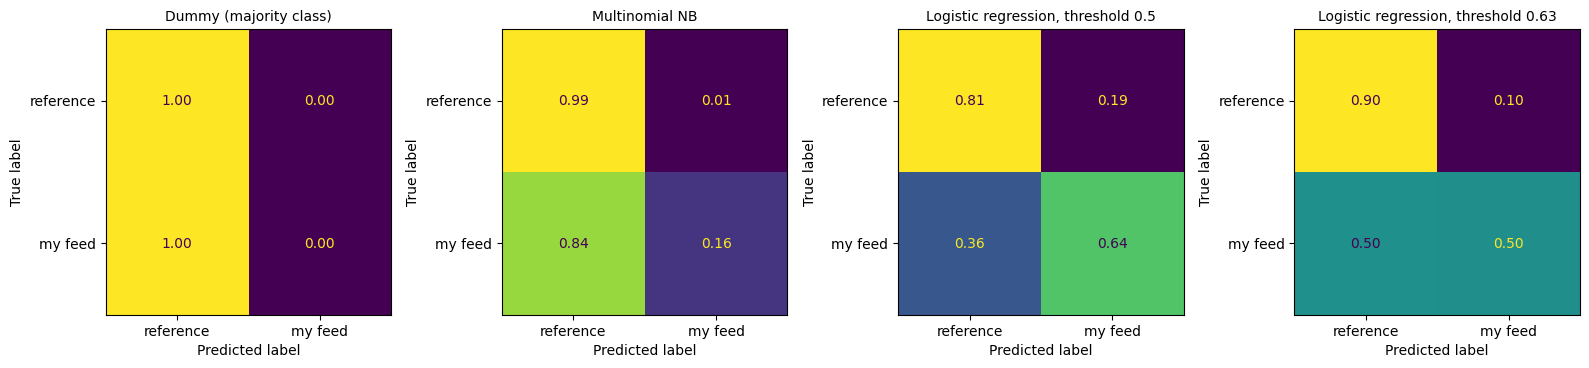

In [31]:
# Normalized confusion matrices for four conditions (rows: true class, sum to 1)
dummy_m = fitted[tuple(sorted(dict(model_name="dummy").items()))]
nb_m = fitted[tuple(sorted(dict(model_name="nb").items()))]
panels = [("Dummy (majority class)", dummy_m.predict(df.loc[te, "lem_stripped"])),
          ("Multinomial NB", nb_m.predict(df.loc[te, "lem_stripped"])),
          ("Logistic regression, threshold 0.5", (p_test >= 0.5).astype(int)),
          (f"Logistic regression, threshold {THRESHOLD:.2f}", (p_test >= THRESHOLD).astype(int))]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (title, pr) in zip(axes, panels):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pr, normalize="true"),
                           display_labels=["reference", "my feed"]).plot(ax=ax, colorbar=False, values_format=".2f",
                                                                         cmap="Blues", im_kw={"vmin": 0, "vmax": 1})
    ax.set_title(title, fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2b_confusion_conditions.png", dpi=150, bbox_inches="tight")

# Where the errors fall: share of each channel's test posts predicted as "my feed" (tuned threshold).
# For my four channels this is recall; for the others it is the false-positive rate.
per_channel = (pd.DataFrame({"channel": df.loc[te, "channel"], "pred": (p_test >= THRESHOLD).astype(int)})
                 .groupby("channel").pred.agg(["mean", "size"])
                 .rename(columns={"mean": "share predicted 'my feed'", "size": "test posts"})
                 .join(CHANNELS.set_index("handle")[["group"]])
                 .sort_values("share predicted 'my feed'", ascending=False))
per_channel.round(3)

## 5. Topic model: first LDA run

Latent Dirichlet Allocation (not covered in class) treats each document as a mixture of $K$ topics and each topic as a distribution over words:

$$\theta_d \sim \text{Dir}(\alpha), \quad z_{dn} \sim \text{Cat}(\theta_d), \quad w_{dn} \sim \text{Cat}(\beta_{z_{dn}})$$

Fitting gives a topic distribution $\theta_d$ for every post. A channel's profile $\theta_s$ is the mean of $\theta_d$ over its posts, so each channel counts equally regardless of how much it publishes. This first run chooses $K$ by held-out perplexity; Section 5b replaces it with a selection by coherence and stability.

In [32]:
import joblib

# First LDA run: K chosen by held-out perplexity on the temporal test period
LDA_CACHE = CACHE_DIR / "lda_v1.joblib"
tr_mask = (df.date_utc < cutoff).to_numpy()

if LDA_CACHE.exists() and CACHED:
    count_vec, lda, perp = joblib.load(LDA_CACHE)
    C_all = count_vec.transform(df.lem_stripped)
    K = lda.n_components
    print(f"loaded topic model from {LDA_CACHE}")
else:
    count_vec = CountVectorizer(min_df=5, max_df=0.5)
    C_all = count_vec.fit_transform(df.lem_stripped)
    perp = {}
    for k in [8, 12, 16, 24]:
        lda_k = LatentDirichletAllocation(n_components=k, learning_method="online", random_state=RNG_SEED,
                                          max_iter=20, n_jobs=1).fit(C_all[tr_mask])
        perp[k] = lda_k.perplexity(C_all[~tr_mask])
    K = min(perp, key=perp.get)
    lda = LatentDirichletAllocation(n_components=K, learning_method="online", random_state=RNG_SEED,
                                    max_iter=30, n_jobs=1).fit(C_all)
    joblib.dump((count_vec, lda, perp), LDA_CACHE)
    print(f"saved topic model to {LDA_CACHE}")
print("held-out perplexity:", {k: round(v) for k, v in perp.items()}, "-> K =", K)

# Topic mix per post and the main topic of each post
theta_d = lda.transform(C_all)
df["topic"] = theta_d.argmax(axis=1)

words = np.array(count_vec.get_feature_names_out())
topic_words = pd.Series({k: " ".join(words[np.argsort(lda.components_[k])[::-1][:10]]) for k in range(K)},
                        name="top lemmas")
topic_words

loaded topic model from /content/drive/MyDrive/cs156-news-diet/lda_v1.joblib
held-out perplexity: {8: 5010, 12: 5406, 16: 5873, 24: 6800} -> K = 8


,top lemmas
0,видео ракета время семья ребенок день новый че...
1,сша страна трамп санкция против ес заявить аме...
2,год российский рф млрд рубль млн россия компан...
3,год выборы дело россия суд человек госдума зад...
4,компания самолет мочь система сообщить работа ...
5,беларусь год страна новый президент первый раз...
6,область атака удар сообщить человек пострадать...
7,украина россия заявить путин война российский ...


## 5b. Improving the topic model

The first LDA run (K = 8, chosen by perplexity) had two problems. Held-out perplexity rose steadily with K, so it simply picked the smallest value offered. And one topic (T0) was held together by format words (видео, смотреть, читать, канал) rather than by a subject. This section changes three things and compares two methods.

1. **News stopwords.** Reporting verbs (сообщить, заявить, отметить), time words (год, день, время) and format words (видео, фото, читать, подробнее, канал) appear under every subject. They are removed from the topic-model vocabulary only. The classifier in Section 4 keeps them, because they are part of an outlet's style.
2. **K chosen by coherence and stability** instead of perplexity, over K = 8 to 30.
3. **Two methods:** LDA on word counts and NMF on TF-IDF.

**Coherence (NPMI).** For a topic's top 10 words, normalized pointwise mutual information measures how much more often two words occur in the same post than they would by chance:

$$\text{NPMI}(w_i, w_j) = \frac{\log \dfrac{P(w_i, w_j)}{P(w_i)\,P(w_j)}}{-\log P(w_i, w_j)} \in [-1, 1]$$

where $P(w)$ is the share of posts containing $w$ and $P(w_i, w_j)$ the share containing both. A topic's coherence is the mean NPMI over all pairs of its top words; a model's coherence is the mean over its topics.

**Stability.** Each candidate is fitted with three random seeds. The adjusted Rand index (ARI) between the seeds' post-to-topic assignments shows whether the same topics come back. A topic structure that changes with the seed is noise.

**NMF** (not covered in class) factorizes the post–term TF-IDF matrix as $X \approx WH$ with $W, H \geq 0$, minimizing $\lVert X - WH \rVert_F^2$. Rows of $H$ are topics; row $i$ of $W$, normalized to sum to 1, is post $i$'s topic mix.

To keep the search fast, LDA candidates are fitted on a random sample of 12,000 posts. Stability is measured on that sample and the echo score on all posts. The chosen model is then refitted on the full corpus.

In [33]:
import joblib
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity

pd.set_option("display.max_colwidth", None)

# News stoplist: reporting verbs, time words and format words that appear under every subject
NEWS_STOP = set("""
сообщить сообщать заявить заявлять отметить отмечать добавить добавлять рассказать рассказывать
сказать говорить напомнить напоминать передать передавать уточнить уточнять подчеркнуть пояснить
написать писать объявить объявлять считать стать мочь являться находиться получить
год день время неделя месяц сегодня вчера завтра утро вечер ночь ранее позже сейчас
новый первый второй третий последний главный большой
человек число часть место раз случай ряд вопрос слово
видео фото фотография смотреть читать подробнее подробный канал подписаться ссылка источник
сайт эфир выпуск материал новость telegram youtube vpn
также пока еще уже более менее около
""".split())

# Which lemmas appear in the largest share of posts, and which of them the stoplist removes
_cv = CountVectorizer(min_df=5, binary=True)
_B = _cv.fit_transform(df.lem_stripped)
_share = np.asarray(_B.mean(axis=0)).ravel()
_vocab = _cv.get_feature_names_out()
_top = np.argsort(_share)[::-1][:40]
display(pd.DataFrame({"lemma": _vocab[_top], "share of posts": _share[_top].round(3),
                      "news stopword": [w in NEWS_STOP for w in _vocab[_top]]}).set_index("lemma").T)

# Topic-model vocabulary: counts for LDA (C2), TF-IDF for NMF (T2), binary matrix for coherence (X_bin)
topic_vec = CountVectorizer(min_df=5, max_df=0.3, stop_words=sorted(NEWS_STOP))
C2 = topic_vec.fit_transform(df.lem_stripped)
T2 = TfidfTransformer(sublinear_tf=True).fit_transform(C2)
words2 = topic_vec.get_feature_names_out()
X_bin = (C2 > 0).astype(np.float32).tocsc()
print(f"topic vocabulary: {len(words2):,} lemmas (first LDA run: {len(words):,})")


def npmi_coherence(components, Xb, top_n=10):
    """Mean NPMI over pairs of each topic's top words, from post-level co-occurrence in Xb."""
    n = Xb.shape[0]
    scores = []
    for comp in components:
        top = np.argsort(comp)[::-1][:top_n]
        sub = Xb[:, top]
        co = (sub.T @ sub).toarray() / n
        p = np.diag(co).copy()
        vals = []
        for i in range(top_n):
            for j in range(i + 1, top_n):
                pij = co[i, j]
                vals.append(-1.0 if pij == 0 else np.log(pij / (p[i] * p[j])) / -np.log(pij))
        scores.append(np.mean(vals))
    return np.array(scores)


def doc_topics(model, method, rows=None):
    """Topic mix per post (rows sum to 1). Posts with no topic words get a uniform mix."""
    X = C2 if method == "lda" else T2
    W = model.transform(X if rows is None else X[rows])
    s = W.sum(axis=1, keepdims=True)
    return np.where(s > 0, W / np.where(s > 0, s, 1), 1.0 / W.shape[1])


def jsd(q, p, eps=1e-12):
    """Jensen-Shannon divergence in base 2; works row-wise on 2-D arrays."""
    q, p = np.asarray(q) + eps, np.asarray(p) + eps
    q, p = q / q.sum(-1, keepdims=True), p / p.sum(-1, keepdims=True)
    m = 0.5 * (q + p)
    kl = lambda a, b: (a * np.log2(a / b)).sum(-1)
    return 0.5 * kl(q, m) + 0.5 * kl(p, m)


# Reading weights of my four channels and every possible four-channel feed (for the null model)
w = CHANNELS.set_index("handle").loc[DIET, "weight"].to_numpy()
_diet_idx = [ALL_CHANNELS.index(c) for c in DIET]
_combos4 = np.array(list(combinations(range(len(ALL_CHANNELS)), len(DIET))))


def echo_and_percentile(theta):
    """Echo score of my feed (reading weights) and the equal-weight feed's percentile among all feeds of the same size."""
    th_s = pd.DataFrame(theta, index=df.channel.values).groupby(level=0).mean().reindex(ALL_CHANNELS).to_numpy()
    p = th_s.mean(axis=0)
    echo_w = jsd(w @ th_s[_diet_idx], p)
    echo_eq = jsd(th_s[_diet_idx].mean(axis=0), p)
    null_same_size = jsd(th_s[_combos4].mean(axis=1), p[None, :])
    return echo_w, (null_same_size < echo_eq).mean() * 100


base_coherence = npmi_coherence(lda.components_, (C_all > 0).astype(np.float32).tocsc()).mean()
print(f"first LDA run (K = {lda.n_components}, no news stopwords): coherence {base_coherence:.3f}")

lemma,россия,год,заявить,сообщить,российский,украина,человек,мочь,рф,новый,...,первый,получить,дело,война,власть,результат,выборы,работа,трамп,против
share of posts,0.252,0.216,0.2,0.196,0.187,0.172,0.147,0.138,0.122,0.121,...,0.083,0.079,0.078,0.078,0.078,0.073,0.072,0.07,0.069,0.067
news stopword,False,True,True,True,False,False,True,True,False,True,...,True,True,False,False,False,False,False,False,False,False


topic vocabulary: 15,816 lemmas (first LDA run: 15,894)
first LDA run (K = 8, no news stopwords): coherence 0.158


In [34]:
# Fit LDA and NMF for each K with three seeds; record coherence, stability (ARI) and my feed's echo percentile
SELECT_CACHE = CACHE_DIR / "topic_selection_v1.joblib"
KS = [8, 12, 16, 20, 25, 30]
SEEDS = [0, 1, 2]

if SELECT_CACHE.exists() and CACHED:
    sel_rows, sel_theta = joblib.load(SELECT_CACHE)
    print(f"loaded model-selection results from {SELECT_CACHE}")
else:
    sample = np.random.default_rng(RNG_SEED).choice(C2.shape[0], size=min(12000, C2.shape[0]), replace=False)
    sel_rows, sel_theta = [], {}
    for method in ("lda", "nmf"):
        for k in KS:
            assigns, cohs = [], []
            for seed in SEEDS:
                if method == "lda":
                    m = LatentDirichletAllocation(n_components=k, learning_method="online", max_iter=10,
                                                  random_state=seed, n_jobs=1).fit(C2[sample])
                else:
                    m = NMF(n_components=k, init="nndsvdar", random_state=seed, max_iter=400).fit(T2)
                assigns.append(doc_topics(m, method, rows=sample).argmax(axis=1))
                cohs.append(npmi_coherence(m.components_, X_bin).mean())
                if seed == SEEDS[0]:
                    th_full = doc_topics(m, method)
                    sel_theta[(method, k)] = th_full.astype(np.float32)
                    e, pct = echo_and_percentile(th_full)
            ari = np.mean([adjusted_rand_score(a, b) for a, b in combinations(assigns, 2)])
            sel_rows.append(dict(method=method, K=k, coherence=np.mean(cohs), stability_ARI=ari,
                                 echo=e, echo_percentile=pct))
            print(f"{method} K={k}: coherence {np.mean(cohs):.3f}, stability {ari:.2f}, echo {e:.4f}, percentile {pct:.0f}")
    joblib.dump((sel_rows, sel_theta), SELECT_CACHE)

selection = pd.DataFrame(sel_rows)
selection.round(3)

loaded model-selection results from /content/drive/MyDrive/cs156-news-diet/topic_selection_v1.joblib


,method,K,coherence,stability_ARI,echo,echo_percentile
0,lda,8,0.171,0.218,0.002,7.688
1,lda,12,0.178,0.229,0.002,2.735
2,lda,16,0.177,0.176,0.002,3.457
3,lda,20,0.149,0.206,0.002,6.992
4,lda,25,0.143,0.180,0.004,12.590
5,lda,30,0.114,0.168,0.004,12.771
6,nmf,8,0.291,0.995,0.002,3.870
7,nmf,12,0.308,0.692,0.003,5.237
8,nmf,16,0.325,0.769,0.003,1.213
9,nmf,20,0.337,0.590,0.003,1.161


**Selection rule.** Among candidates whose stability (mean ARI across seeds) is at least 0.5, take the one with the highest coherence. The rule was fixed before reading the topics.

chosen: NMF with K = 20 (coherence 0.337, stability 0.59; first LDA run coherence 0.158)


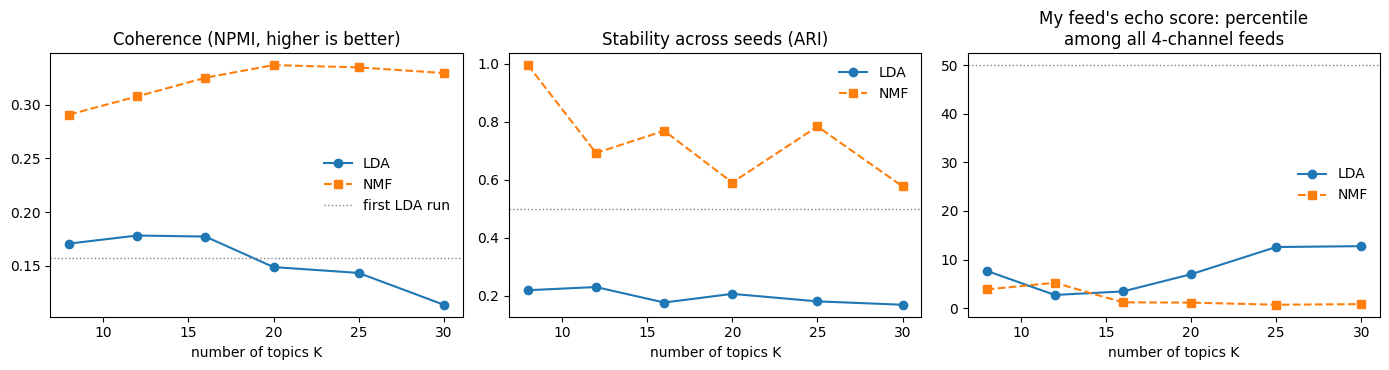

In [35]:
# Apply the selection rule and plot coherence, stability and echo percentile against K
MIN_STABILITY = 0.5
eligible = selection[selection.stability_ARI >= MIN_STABILITY]
best_row = (eligible if len(eligible) else selection).sort_values("coherence", ascending=False).iloc[0]
FINAL_METHOD, FINAL_K = best_row.method, int(best_row.K)
print(f"chosen: {FINAL_METHOD.upper()} with K = {FINAL_K} "
      f"(coherence {best_row.coherence:.3f}, stability {best_row.stability_ARI:.2f}; "
      f"first LDA run coherence {base_coherence:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for method, style in (("lda", "o-"), ("nmf", "s--")):
    sub = selection[selection.method == method]
    axes[0].plot(sub.K, sub.coherence, style, label=method.upper())
    axes[1].plot(sub.K, sub.stability_ARI, style, label=method.upper())
    axes[2].plot(sub.K, sub.echo_percentile, style, label=method.upper())
axes[0].axhline(base_coherence, color="0.5", lw=1, ls=":", label="first LDA run")
axes[0].set_title("Coherence (NPMI, higher is better)")
axes[1].axhline(MIN_STABILITY, color="0.5", lw=1, ls=":")
axes[1].set_title("Stability across seeds (ARI)")
axes[2].axhline(50, color="0.5", lw=1, ls=":")
axes[2].set_title("My feed's echo score: percentile\namong all 4-channel feeds")
for ax in axes:
    ax.set_xlabel("number of topics K")
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig5_topic_model_selection.png", dpi=150, bbox_inches="tight")

In [36]:
# Refit the chosen model on all posts; print its topics, typical posts and any overlapping topic pairs
FINAL_CACHE = CACHE_DIR / f"topic_final_{FINAL_METHOD}_{FINAL_K}_v1.joblib"
if FINAL_CACHE.exists() and CACHED:
    final_model = joblib.load(FINAL_CACHE)
    print(f"loaded final topic model from {FINAL_CACHE}")
else:
    if FINAL_METHOD == "lda":
        final_model = LatentDirichletAllocation(n_components=FINAL_K, learning_method="online", max_iter=30,
                                                random_state=RNG_SEED, n_jobs=1).fit(C2)
    else:
        final_model = NMF(n_components=FINAL_K, init="nndsvda", max_iter=600, random_state=RNG_SEED).fit(T2)
    joblib.dump(final_model, FINAL_CACHE)

# From here on, the metrics in Section 6 use this model
K = FINAL_K
theta_d = doc_topics(final_model, FINAL_METHOD)
df["topic"] = theta_d.argmax(axis=1)
words = words2
topic_words = pd.Series({k: " ".join(words2[np.argsort(final_model.components_[k])[::-1][:12]]) for k in range(K)},
                        name="top lemmas")
display(topic_words.to_frame())

# Three most typical posts per topic, to label the topics by hand
for k in range(K):
    print(f"\nT{k}: {topic_words[k]}")
    for i in np.argsort(theta_d[:, k])[::-1][:3]:
        print(f"    {df.channel.iloc[i]:<16} {df.text_stripped.iloc[i][:140]}")

# Topics that share vocabulary (cosine similarity of topic-word weights above 0.4)
_tw = final_model.components_ / final_model.components_.sum(axis=1, keepdims=True)
_sim = cosine_similarity(_tw)
_pairs = [(f"T{i}", f"T{j}", round(_sim[i, j], 2)) for i in range(K) for j in range(i + 1, K) if _sim[i, j] > 0.4]
print("\ntopic pairs with cosine similarity > 0.4:", _pairs or "none")

loaded final topic model from /content/drive/MyDrive/cs156-news-diet/topic_final_nmf_20_v1.joblib


,top lemmas
0,удар нанести объект российский инфраструктура украина киев наносить зеленский энергетика нпз энергетический
1,пострадать погибнуть атака результат дом повредить бпнуть губернатор ребенок жилой пожар автомобиль
2,выборы госдума партия цик голосование единый голос протокол кандидат яблоко участок кпрф
3,рф поразить вс мо порт всу груз минобороны центр одесса сухогруз логистический
4,уиткофф кушнер москва переговоры киев стив зеленский визит спецпосланник встреча американский представитель
5,сбить пво регион бпнуть минобороны сила беспилотник средство украинский собянин уничтожить россия
6,трамп сша дональд иран президент американский встреча белый си цзиньпин вашингтон зеленский
7,дело суд задержать уголовный признать мужчина возбудить приговорить колония следствие бывший полиция
8,путин владимир президент саммит встреча песок кремль брикс рф ушаков российский лидер
9,киев район прилет кличко паблик здание местный пожар мэр соломенский склад голосеевский



T0: удар нанести объект российский инфраструктура украина киев наносить зеленский энергетика нпз энергетический
    stranaua         Видео разрушений в столичном КВЦ "Парковый" после дневного удара опубликовала ГСЧС. Напомним, вечером по нему был нанесен повторный удар.
    stranaua         По Краматорску нанесен удар двумя авиабомбами, сообщает ГСНС. Удар пришелся по жилой застройке и объектам инфраструктуры.
    belta_telegramm  Наводнения нанесли серьезный удар по туризму в Непале в разгар сезона

T1: пострадать погибнуть атака результат дом повредить бпнуть губернатор ребенок жилой пожар автомобиль
    belta_telegramm  На Синайском полуострове в Египте автобус попал в ДТП, погибли 16 человек, 28 пострадали
    tass_agency      Предварительно, 2 человека погибли, 3 пострадали после схода лавины в горах Кабардино-Балкарии, еще 10 человек остаются под лавиной, сообщил
    rian_ru          Минимум 25 человек погибли в Кабо-Верде – автобус рухнул с 30-метрового обрыва. Как передает RTP

## 5c. Agenda or style? The classifier on topic features

On TF-IDF, the classifier recognizes my feed well inside the corpus (ROC-AUC 0.82) but not at all on a channel it has never seen (leave-one-channel-out ROC-AUC 0.50). That suggests it learned the *style* of my four channels rather than what they cover. To test this, the same logistic regression is trained on a different representation: each post's topic mix from the final topic model (Section 5b), which contains subject matter and nothing else. If topic features generalize to unseen channels better than TF-IDF does, the difference between my feed and the basket is partly an agenda difference that a model can learn; if not, the content difference is too small to learn at the level of single posts, which is consistent with the low echo score.

In [37]:
# Logistic regression on each post's topic mix instead of its words (temporal split and leave-one-channel-out)
topic_feats = theta_d
tr, te = get_split("temporal")
lr_topics = LogisticRegression(class_weight="balanced", max_iter=3000)
lr_topics.fit(topic_feats[tr], df.loc[tr, "y"])
auc_topics_temporal = roc_auc_score(df.loc[te, "y"], lr_topics.predict_proba(topic_feats[te])[:, 1])

oof_topics = cross_val_predict(LogisticRegression(class_weight="balanced", max_iter=3000), topic_feats, df.y,
                               groups=df.channel, cv=LeaveOneGroupOut(), method="predict_proba")[:, 1]
auc_topics_loco = roc_auc_score(df.y, oof_topics)

agenda_vs_style = pd.DataFrame({
    "features": ["TF-IDF (lemmas)", f"topic mix ({FINAL_METHOD.upper()}, K = {K})"],
    "ROC-AUC, temporal split": [results.loc[(results.model == "lr") & (results.split == "temporal")
                                            & (results.text == "lem_stripped") & (results.ngram == "1-1"), "ROC_AUC"].iloc[0],
                                auc_topics_temporal],
    "ROC-AUC, leave one channel out": [roc_auc_score(df.y, oof_holdout), auc_topics_loco],
})
agenda_vs_style.round(3)

,features,"ROC-AUC, temporal split","ROC-AUC, leave one channel out"
0,TF-IDF (lemmas),0.821,0.503
1,"topic mix (NMF, K = 20)",0.606,0.370


**Topic labels.** I label each topic of the model chosen in Section 5b by hand, from its top lemmas and its most typical posts printed above. From here on, all metrics use that model.

In [38]:
# Topic labels, written by hand from the top lemmas and typical posts printed in Section 5b
TOPIC_LABELS = {k: f"T{k}" for k in range(K)}
if (FINAL_METHOD, K) == ("nmf", 20):   # read from the top words and typical posts printed in Section 5b
    TOPIC_LABELS = {
        0: "T0 Strikes on Ukrainian infrastructure", 1: "T1 Casualties and accidents",
        2: "T2 Russian Duma elections", 3: "T3 Russian MoD: strikes on Odesa port",
        4: "T4 US–Russia talks (Witkoff, Kushner)", 5: "T5 Air defence: drones shot down over Russia",
        6: "T6 Trump and US politics", 7: "T7 Courts and criminal cases",
        8: "T8 Putin: summits and Kremlin", 9: "T9 Strikes on Kyiv: local reports",
        10: "T10 Russia, Europe and NATO", 11: "T11 Flydubai incident and aviation",
        12: "T12 Belarus: Lukashenko and state agenda", 13: "T13 Drone and missile attacks",
        14: "T14 Economy, budgets and companies", 15: "T15 Sanctions",
        16: "T16 Front line: territorial control claims", 17: "T17 Ukraine: prosecutor general and anti-corruption",
        18: "T18 Oil and fuel prices", 19: "T19 Germany and Russian diplomacy",
    }

# Channel topic profiles: the mean topic mix of each channel's posts
theta_s = (pd.DataFrame(theta_d, index=df.channel).groupby(level=0).mean()
             .reindex(ALL_CHANNELS))
theta_s.columns = [TOPIC_LABELS[k] for k in range(K)]
theta_s.round(3)

,T0 Strikes on Ukrainian infrastructure,T1 Casualties and accidents,T2 Russian Duma elections,T3 Russian MoD: strikes on Odesa port,"T4 US–Russia talks (Witkoff, Kushner)",T5 Air defence: drones shot down over Russia,T6 Trump and US politics,T7 Courts and criminal cases,T8 Putin: summits and Kremlin,T9 Strikes on Kyiv: local reports,"T10 Russia, Europe and NATO",T11 Flydubai incident and aviation,T12 Belarus: Lukashenko and state agenda,T13 Drone and missile attacks,"T14 Economy, budgets and companies",T15 Sanctions,T16 Front line: territorial control claims,T17 Ukraine: prosecutor general and anti-corruption,T18 Oil and fuel prices,T19 Germany and Russian diplomacy
channel,,,,,,,,,,,,,,,,,,,,
nexta_live,0.031,0.054,0.030,0.019,0.030,0.020,0.050,0.093,0.065,0.044,0.105,0.056,0.024,0.086,0.109,0.038,0.032,0.029,0.037,0.049
Ateobreaking,0.017,0.056,0.089,0.052,0.027,0.023,0.069,0.072,0.072,0.023,0.084,0.050,0.021,0.043,0.091,0.051,0.025,0.023,0.049,0.062
theinsider,0.021,0.043,0.056,0.022,0.016,0.022,0.041,0.140,0.043,0.017,0.066,0.038,0.019,0.065,0.175,0.056,0.039,0.026,0.050,0.043
zerkalo_io,0.010,0.048,0.015,0.012,0.019,0.010,0.036,0.143,0.024,0.023,0.058,0.041,0.191,0.042,0.181,0.033,0.019,0.022,0.041,0.033
rian_ru,0.018,0.074,0.043,0.030,0.039,0.044,0.042,0.084,0.082,0.025,0.085,0.035,0.018,0.039,0.124,0.030,0.071,0.019,0.048,0.049
tass_agency,0.013,0.063,0.058,0.110,0.033,0.041,0.032,0.078,0.078,0.019,0.069,0.036,0.014,0.025,0.100,0.037,0.063,0.025,0.037,0.072
rbc_news,0.012,0.031,0.051,0.011,0.037,0.035,0.053,0.071,0.077,0.010,0.074,0.033,0.023,0.029,0.217,0.049,0.032,0.029,0.065,0.060
kommersant,0.010,0.046,0.063,0.028,0.031,0.038,0.043,0.100,0.083,0.011,0.059,0.034,0.018,0.020,0.186,0.042,0.025,0.020,0.089,0.056
meduzalive,0.020,0.055,0.078,0.018,0.028,0.018,0.039,0.118,0.048,0.022,0.098,0.037,0.028,0.053,0.157,0.049,0.027,0.029,0.031,0.048


## 6. Metrics

**Echo score.** The reference distribution is the unweighted mean over all basket channels $R$; my diet $D$ is weighted by reading share $w_s$:

$$p_R = \frac{1}{|R|}\sum_{s\in R}\theta_s, \qquad q_D = \sum_{s\in D} w_s\,\theta_s, \qquad \text{Echo}(D) = \text{JSD}(q_D \,\|\, p_R)$$

$$\text{JSD}(q\,\|\,p) = \tfrac12 \text{KL}(q\,\|\,m) + \tfrac12 \text{KL}(p\,\|\,m), \quad m = \tfrac12 (q+p)$$

In base 2, JSD lies in $[0, 1]$. Unlike KL, it is symmetric and stays finite when a topic is absent from one side.

**Coverage gap per topic:** $g_k = \log\big(q_{D,k}/p_{R,k}\big)$. Negative values are topics I see less often than the basket average.

Echo(D) = 0.0038


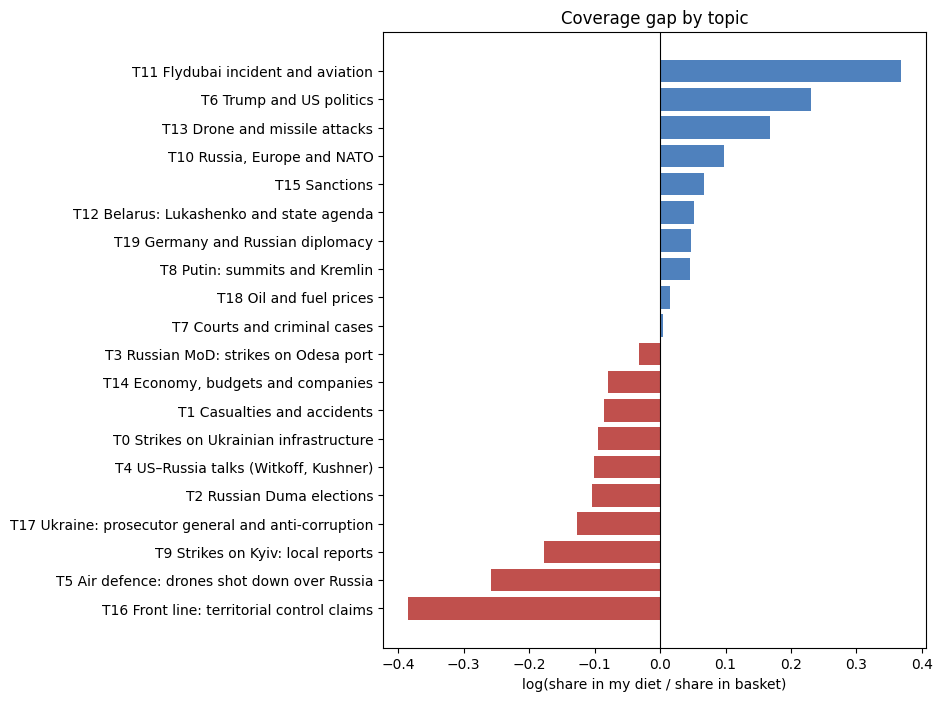

In [69]:
# Echo score of my feed (reading weights) and coverage gap per topic
# (jsd() and the reading weights w are defined in Section 5b)
p_R = theta_s.mean(axis=0).to_numpy()                 # basket: unweighted mean of all 19 channel profiles
q_D = w @ theta_s.loc[DIET].to_numpy()                # my feed: reading-weighted mix of my four channels
echo = jsd(q_D, p_R)
gap = pd.Series(np.log(q_D / p_R), index=theta_s.columns).sort_values()
print(f"Echo(D) = {echo:.4f}")

fig, ax = plt.subplots(figsize=(7, 0.35 * K + 1))
ax.barh(gap.index, gap.values, color=np.where(gap.values < 0, "#c0504d", "#4f81bd"))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("log(share in my diet / share in basket)")
ax.set_title("Coverage gap by topic")
fig.savefig(FIG_DIR / "fig3_topic_gap.png", dpi=150, bbox_inches="tight")

### Null model: is my diet narrower than a random one?
With 19 channels there are $2^{19}-1 = 524{,}287$ non-empty subsets, so every one can be scored (equal weights within a subset). The figure places my diet in the distribution of subsets of the same size.

equal-weight diet echo = 0.0034; higher than 1.8% of all 3876 4-channel diets


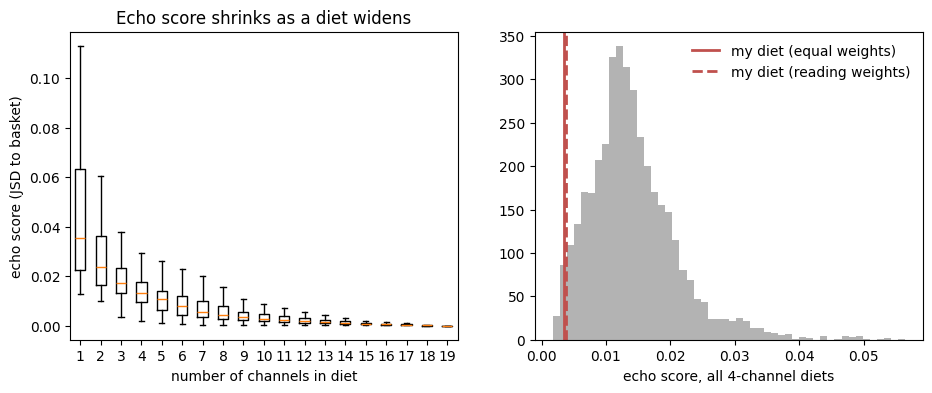

In [70]:
# Null model: score every equal-weight feed of every size (all 2^19 - 1 subsets)
Theta = theta_s.to_numpy()
n_ch = len(ALL_CHANNELS)
null = {}
for k in range(1, n_ch + 1):
    combos = np.array(list(combinations(range(n_ch), k)))
    mixes = Theta[combos].mean(axis=1)
    null[k] = jsd(mixes, p_R[None, :])

# Percentile of my equal-weight feed among all four-channel feeds
k_diet = len(DIET)
diet_equal = jsd(theta_s.loc[DIET].mean(axis=0).to_numpy(), p_R)
pct = (null[k_diet] < diet_equal).mean() * 100
print(f"equal-weight diet echo = {diet_equal:.4f}; higher than {pct:.1f}% of all {len(null[k_diet])} {k_diet}-channel diets")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].boxplot([null[k] for k in range(1, n_ch + 1)], showfliers=False)
axes[0].set_xlabel("number of channels in diet")
axes[0].set_ylabel("echo score (JSD to basket)")
axes[0].set_title("Echo score shrinks as a diet widens")
axes[1].hist(null[k_diet], bins=50, color="0.7")
axes[1].axvline(diet_equal, color="#c0504d", lw=2, label="my diet (equal weights)")
axes[1].axvline(echo, color="#c0504d", lw=2, ls="--", label="my diet (reading weights)")
axes[1].set_xlabel(f"echo score, all {k_diet}-channel diets")
axes[1].legend(frameon=False)
fig.savefig(FIG_DIR / "fig4_null_model.png", dpi=150, bbox_inches="tight")

### Uncertainty and sensitivity
**Bootstrap.** Resample posts with replacement within each channel, recompute every $\theta_s$, and recompute the echo score; repeated $B=300$ times.

**Leave one channel out of the basket.** Drop each reference channel in turn and recompute $p_R$. A large swing means the result depends on my choice of basket.

In [71]:
# Bootstrap: resample posts within each channel, recompute the profiles and the echo score
B = 300
rng = np.random.default_rng(RNG_SEED)
idx_by_ch = {ch: np.where(df.channel.to_numpy() == ch)[0] for ch in ALL_CHANNELS}
boot = []
for _ in range(B):
    th = np.vstack([theta_d[rng.choice(ix, size=len(ix), replace=True)].mean(axis=0) for ix in idx_by_ch.values()])
    th = pd.DataFrame(th, index=ALL_CHANNELS)
    boot.append(jsd(w @ th.loc[DIET].to_numpy(), th.mean(axis=0).to_numpy()))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Echo(D) = {echo:.4f}, 95% bootstrap interval [{lo:.4f}, {hi:.4f}]")

# Sensitivity to the basket: drop each reference channel in turn and recompute the basket average
loo = {ch: jsd(q_D, theta_s.drop(index=ch).mean(axis=0).to_numpy())
       for ch in ALL_CHANNELS if ch not in DIET}
pd.Series(loo, name="echo without this channel").sort_values().round(4)

Echo(D) = 0.0038, 95% bootstrap interval [0.0032, 0.0046]


,echo without this channel
stranaua,0.0035
rian_ru,0.0035
novaya_europe,0.0036
tvrain,0.0037
rybar,0.0037
tass_agency,0.0037
uniannet,0.0038
currenttime,0.0038
kommersant,0.0038
rbc_news,0.0039


### Sensitivity to reading weights
The reading weights $w_s$ are my own estimate, not measured. To see whether the result depends on them, I draw 2,000 weightings of my four channels from a flat Dirichlet distribution (every weighting that sums to 1 is equally likely) and recompute the echo score and its percentile among all four-channel feeds for each draw. I also check how often the three most under-covered topics stay the same as under my weights, and the echo score of each channel on its own.

echo score over 2,000 random weightings: median 0.0078, 90% of draws in [0.0040, 0.0213] (my weights: 0.0038; equal weights: 0.0034)
percentile among 4-channel feeds: median 16.2%, 90% of draws in [3.2%, 87.9%]
draws whose echo is below the median 4-channel feed: 80%
average overlap of the three most under-covered topics with my weights' top three: 61%


,echo if I read only this channel
NEXTA Live,0.0200
Ateo Breaking,0.0315
The Insider,0.0180
Zerkalo,0.0530


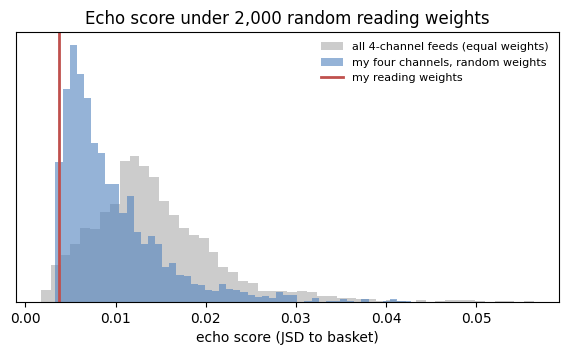

In [83]:
# 2,000 random reading weightings of my four channels (flat Dirichlet)
W_DRAWS = np.random.default_rng(RNG_SEED + 1).dirichlet(np.ones(len(DIET)), size=2000)
D_theta = theta_s.loc[DIET].to_numpy()
echo_w = jsd(W_DRAWS @ D_theta, p_R[None, :])
pct_w = (null[k_diet][None, :] < echo_w[:, None]).mean(axis=1) * 100

# How often the three most under-covered topics stay the same
top3_mine = set(gap.index[:3])
gaps_w = np.log((W_DRAWS @ D_theta) / p_R[None, :])
top3_overlap = np.array([len(set(theta_s.columns[np.argsort(g)[:3]]) & top3_mine) / 3 for g in gaps_w])

# Echo score if I read only one of my channels
single = pd.Series({CHANNELS.set_index("handle").name[ch]: jsd(theta_s.loc[ch].to_numpy(), p_R) for ch in DIET},
                   name="echo if I read only this channel")
print(f"echo score over 2,000 random weightings: median {np.median(echo_w):.4f}, "
      f"90% of draws in [{np.percentile(echo_w, 5):.4f}, {np.percentile(echo_w, 95):.4f}] "
      f"(my weights: {echo:.4f}; equal weights: {diet_equal:.4f})")
print(f"percentile among 4-channel feeds: median {np.median(pct_w):.1f}%, "
      f"90% of draws in [{np.percentile(pct_w, 5):.1f}%, {np.percentile(pct_w, 95):.1f}%]")
print(f"draws whose echo is below the median 4-channel feed: {(echo_w < np.median(null[k_diet])).mean():.0%}")
print(f"average overlap of the three most under-covered topics with my weights' top three: {top3_overlap.mean():.0%}")
display(single.round(4).to_frame())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(null[k_diet], bins=50, color="0.8", density=True, label="all 4-channel feeds (equal weights)")
ax.hist(echo_w, bins=50, color="#4f81bd", alpha=0.6, density=True, label="my four channels, random weights")
ax.axvline(echo, color="#c0504d", lw=2, label="my reading weights")
ax.set_xlabel("echo score (JSD to basket)")
ax.set_yticks([])
ax.legend(frameon=False, fontsize=8)
ax.set_title("Echo score under 2,000 random reading weights")
fig.savefig(FIG_DIR / "fig4b_weight_sensitivity.png", dpi=150, bbox_inches="tight")

### Blind-spot score
For each reference post $i$: $B_i = 1 - \hat P(\text{my diet} \mid x_i)$, using **out-of-fold** probabilities (5-fold stratified), so no post is scored by a model trained on it.

Per topic $k$, the blind-spot rate is the share of the topic's reference posts that the model finds very unlike my diet:

$$\text{BSR}_k(\tau) = \frac{1}{N_k}\sum_{i \in k} \mathbb{1}\big[\hat P(\text{my diet}\mid x_i) < \tau\big]$$

Predicted probabilities shift with class balance, so I report $\tau \in \{0.1, 0.2, 0.3\}$ and check that the topic ranking stays stable across them.

In [72]:
# Out-of-fold probability that each post belongs to my feed (5-fold), so no post is scored by a model trained on it
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RNG_SEED)
lr_best = best.best_estimator_
OOF_CACHE = CACHE_DIR / "model_a_oof_v1.npy"
if OOF_CACHE.exists() and CACHED:
    df["p_diet"] = np.load(OOF_CACHE)
else:
    df["p_diet"] = cross_val_predict(lr_best, df.lem_stripped, df.y, cv=skf, method="predict_proba", n_jobs=-1)[:, 1]
    np.save(OOF_CACHE, df["p_diet"].to_numpy())
df["blind_spot"] = 1 - df["p_diet"]

# Blind-spot rate per topic: share of the topic's basket posts with P(my feed) below tau
ref = df[df.y == 0]
bsr = pd.DataFrame({f"BSR(τ={t})": ref.groupby("topic").p_diet.apply(lambda s: (s < t).mean())
                    for t in (0.1, 0.2, 0.3)})
bsr.index = [TOPIC_LABELS[k] for k in bsr.index]
bsr["n_posts"] = ref.groupby("topic").size().to_numpy()
bsr.sort_values("BSR(τ=0.2)", ascending=False).round(3)

,BSR(τ=0.1),BSR(τ=0.2),BSR(τ=0.3),n_posts
T5 Air defence: drones shot down over Russia,0.480,0.711,0.809,498
T3 Russian MoD: strikes on Odesa port,0.521,0.710,0.803,931
T16 Front line: territorial control claims,0.463,0.692,0.804,1191
T9 Strikes on Kyiv: local reports,0.440,0.607,0.729,1013
"T4 US–Russia talks (Witkoff, Kushner)",0.374,0.560,0.707,700
T1 Casualties and accidents,0.334,0.554,0.683,1679
"T14 Economy, budgets and companies",0.332,0.546,0.689,4657
T17 Ukraine: prosecutor general and anti-corruption,0.322,0.545,0.643,549
T12 Belarus: Lukashenko and state agenda,0.338,0.517,0.641,1619
T2 Russian Duma elections,0.276,0.497,0.644,1456


In [73]:
# Examples at both ends of the classifier's scale
cols = ["channel", "date_utc", "p_diet", "text_stripped"]
print("Reference posts that look most like my diet")
display(ref.nlargest(5, "p_diet")[cols])
print("Diet posts that look least like my diet")
display(df[df.y == 1].nsmallest(5, "p_diet")[cols])
print("Highest blind-spot reference posts")
display(ref.nlargest(5, "blind_spot")[cols])

Reference posts that look most like my diet


,channel,date_utc,p_diet,text_stripped
23951,uniannet,2026-09-25 14:01:50+00:00,0.983819,"Во время сегодняшней российской атаки на Киев погиб 14-летний гражданин Израиля, - The Times of Israel Российский дрон попал в жилой дом в центре столицы, где находилась семья подростка. Его мать госпитализировали с ранениями. Сообщается, что посольство Израиля в Украине и израильский МИД поддерживают связь с семьей погибшего и готовы оказать необходимую помощь."
21034,stranaua,2026-09-22 18:00:47+00:00,0.980681,"Трамп вновь повторил, что и Зеленский, и Путин хотят завершения войны."
16368,uniannet,2026-09-17 17:55:16+00:00,0.976855,"Поляки как-то активизировались: сначала Сикорский обещал быстро победить россию, теперь Туск грозит решительным ответом Премьер Польши заявил, что россия уже ведет против страны гибридную войну — с помощью беспилотников, диверсий и дезинформации. А в ближайшие месяцы ожидаются новые провокации. Но, если же рф решится на прямое нападение, Польша ответит вместе со своими союзниками: «Мы не ищем войны. Но если кто-либо осмелится напасть на нас, он столкнется с решительным ответом — нашим и наших союзников», — заявил Туск."
30380,tass_agency,2026-10-02 08:56:10+00:00,0.974575,"Лукашенко поддержал заявление Путина на ""Валдае"", что мир находится на изломе."
29970,uniannet,2026-10-01 18:33:30+00:00,0.972861,"""Если утрата территорий неизбежно произойдет, есть ли смысл за них цепляться?"", - кремлевский диктатор Гнида также выразила уверенность, что рф ""освободит"" Донбасс гораздо раньше, чем через 1,5-2 года."


Diet posts that look least like my diet


,channel,date_utc,p_diet,text_stripped
9966,theinsider,2026-09-10 16:31:57+00:00,0.005404,"«Логика Путина — это логика эскалации». В Украине перед зимой заканчиваются средства ПВО, российские войска усиливают удары по энергетической инфраструктуре У Украины заканчиваются запасы ракет PAC-3 для систем ПВО Patriot, а страны ЕС и США не могут полностью восполнить этот дефицит на фоне продолжающегося военного конфликта в Иране. Об этом пишет Le Monde. Украина готовится к наступлению холодного сезона, который, по мнению экспертов, опрошенных французской газетой, может оказаться ещё более суровым, чем зима прошлого года. Российские войска сделали энергетическую инфраструктуру страны приоритетной целью, нанося удары по подстанциям, тепловым электростанциям и линиям электропередачи. «Логика Путина — это логика эскалации. Теперь он наносит удары не только по электроснабжению, но и по системам водоснабжения. Путин считает, что время на его стороне, и убежден, что, усилив бомбардировки Украины и её стратегической инфраструктуры, он сможет завоевать оставшиеся в руках украинцев районы Донбасса в течение ближайших шести месяцев, хотя ситуация на фронте не указывает на ничего подобного», — отмечает Грегуар Рус, эксперт аналитического центра Chatham House. Le Monde отмечает, что Киев испытывает нехватку ракет для ПВО, способных защитить города. По данным издания, Украина почти исчерпала запасы ракет-перехватчиков PAC-3 для систем Patriot, а страны НАТО поставляют их в ограниченном количестве на фоне конфликта с Ираном. Между США и Украиной продолжаются переговоры по поводу лицензии на производство Patriot, сообщил госсекретарь Марк Рубио. Однако, по его словам, это не решит проблемы Украины в краткосрочной перспективе. В беседе с Le Monde директор Центра исследований в области безопасности Французского института международных отношений Эли Тененбаум отметила, что произведенные в Украине Patriot могут появиться не ранее, чем через год. ◾ Помочь жителям Украины пережить грядущую зиму можно с помощью денежного перевода благотворительному проекту «Давайте». Оформить пожертвование можно по ссылке. Фото: Александр Бабенко"
4197,theinsider,2026-09-04 12:30:43+00:00,0.010234,"«Алиса AI» может получить расширенные права на устройствах. Это упростит возможную слежку, но говорить о «шпионском ПО» еще рано — эксперты Российское Минцифры обсуждает возможность предоставить ИИ-ассистенту «Алиса AI» от «Яндекса» расширенные права вплоть до доступа к банковским приложениям на смартфонах, сообщил на этой неделе « ». Это вписывается в тренд импортозамещения, но говорить о «шпионском ПО» в лице «Алисы» еще рано, считают опрошенные эксперты. «Алиса AI» наравне с браузером «Яндекса», «Почтой Mail.ru», мессенджером «Макс» с 2027 года станет одним из приложений, обязательных к предустановке на ввозимые устройства. Речь идет именно о том, что при этом ей выдадут доступ к банковским приложениям на устройствах и к другим приложениям, собирающим чувствительные данные. В целом такой ход вписывается в тренд властей, которые пытаются получить технологическое преимущество российских сервисов перед иностранными аналогами с помощью административной поддержки, говорит киберадвокат Саркис Дарбинян: «И это не первый случай. Мы знаем, что российские власти так же двигают „Макс“, а вот теперь и „Алису”. Это часть плана по суверенизации и установки СОРМ по всей стране. Российским властям не нравится, что вместо „Алисы” россияне выбирают Gemini от Google, который есть на Android, и поэтому они хотят пересадить всех на отечественные сервисы, давая последним больше прав». Специалист по информационной безопасности Артем Тамоян также отмечает, что логика решения предоставить «Алисе» доступ к банковским приложениям в целом вписывается в общий тренд, когда люди дают ИИ-агенту больше возможностей и доступов. С точки зрения безопасности это сомнительная инициатива. Кроме того, такой широкий доступ упрощает потенциальную слежку: «Надо понимать, что для нормальной работы ИИ-агенту приходится

Highest blind-spot reference posts


channel                  date_utc    p_diet  \
3686   tass_agency 2026-09-04 01:10:01+00:00  0.000369   
32        rbc_news 2026-09-01 03:04:13+00:00  0.000567   
5613    kommersant 2026-09-06 08:53:45+00:00  0.000628   
27575     stranaua 2026-09-29 17:04:31+00:00  0.000641   
11391        rybar 2026-09-12 07:59:44+00:00  0.000724   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

### What the blind spots look like
For the three topics my feed under-covers most, the basket posts that the classifier finds least like my feed: the clearest examples of what I do not see.

In [74]:
# Three basket posts with the lowest P(my feed) in each of the three most under-covered topics
_label_to_k = {v: k for k, v in TOPIC_LABELS.items()}
_names = CHANNELS.set_index("handle").name
for lab in gap.index[:3]:
    k = _label_to_k[lab]
    sub = ref[ref.topic == k].nsmallest(3, "p_diet")
    print(f"\n=== {lab}  (gap {gap[lab]:.2f}; {len(ref[ref.topic == k]):,} reference posts)")
    for _, r in sub.iterrows():
        print(f"[{_names[r.channel]}, {str(r.date_utc)[:10]}, P(my feed) = {r.p_diet:.3f}]")
        print("   " + r.text_noboiler[:350].replace("\n", " "))


=== T16 Front line: territorial control claims  (gap -0.39; 1,191 reference posts)
[Rybar, 2026-09-12, P(my feed) = 0.001]
   #Сводка на утро 12 сентября 2026 года  ▪️ Ночью противник провел новый массированный налет на российские регионы. Минобороны России сообщило, что с 20:00 до 08:00 перехвачены и уничтожены 230 БПЛА самолётного типа над 12 областями, Крымом, Азовским и Черным морями. В Самарской области атакованы промышленные предприятия, один человек госпитализирова
[TASS, 2026-09-05, P(my feed) = 0.002]
   ▶️ Операторы БПЛА "Востока" сорвали переброску резервов ВСУ в Запорожской области, сообщили в МО РФ.  
[RIA Novosti, 2026-09-14, P(my feed) = 0.002]
   Спецоперация. Обстановка и главные события на 14 сентября:  ▪️Армия России освободила Широкое и Шевченково в районе окружения ВСУ в Харьковской области, а также Новоандреевку в Запорожской области, говорится в сводке Минобороны.  ▪️Идут бои за Малую Волчью, уничтожаются блокированные формирования у Ольховатки, с начала месяца 

## 6b. Framing: how outlets describe the same events

Topic shares measure *what* a feed covers. This section measures *how*, with three transparent methods:

1. **Marker words:** how often each type of outlet uses particular names, sources and distancing words.
2. **Who acts in strike reports:** whether the Russian or the Ukrainian side is named as the attacker, or neither.
3. **Fightin' Words:** the words most distinctive of one group of outlets compared with another, corrected for word frequency.

Matching uses the post text after boilerplate removal, lowercased, with ё replaced by е.

marker occurrences per 10,000 words


bloc,my feed,Russian independent / international,Ukrainian,Russian business,Russian state,Belarusian state,pro-war blog
war: «СВО» / «спецоперация»,2.14,1.97,0.60,1.74,8.84,0.18,9.07
war: «война»,18.09,21.20,28.66,4.57,6.05,6.09,11.18
war: «вторжение»,1.58,2.07,1.14,0.06,0.04,0.00,0.56
army: «ВСУ»,2.96,4.71,5.87,3.05,38.57,0.09,15.81
army: «ЗСУ»,0.00,0.00,0.00,0.00,0.00,0.00,0.00
«киевский режим»,0.23,0.21,0.11,0.51,2.60,0.00,5.27
«белорусский»,0.72,1.22,0.43,1.21,0.31,41.49,0.07
«беларусский»,4.77,0.06,0.05,0.00,0.00,0.00,0.00
«диктатор»,1.51,0.23,0.22,0.00,0.00,0.53,0.00
«политзаключенный»,4.54,2.31,0.19,0.06,0.12,0.18,0.42


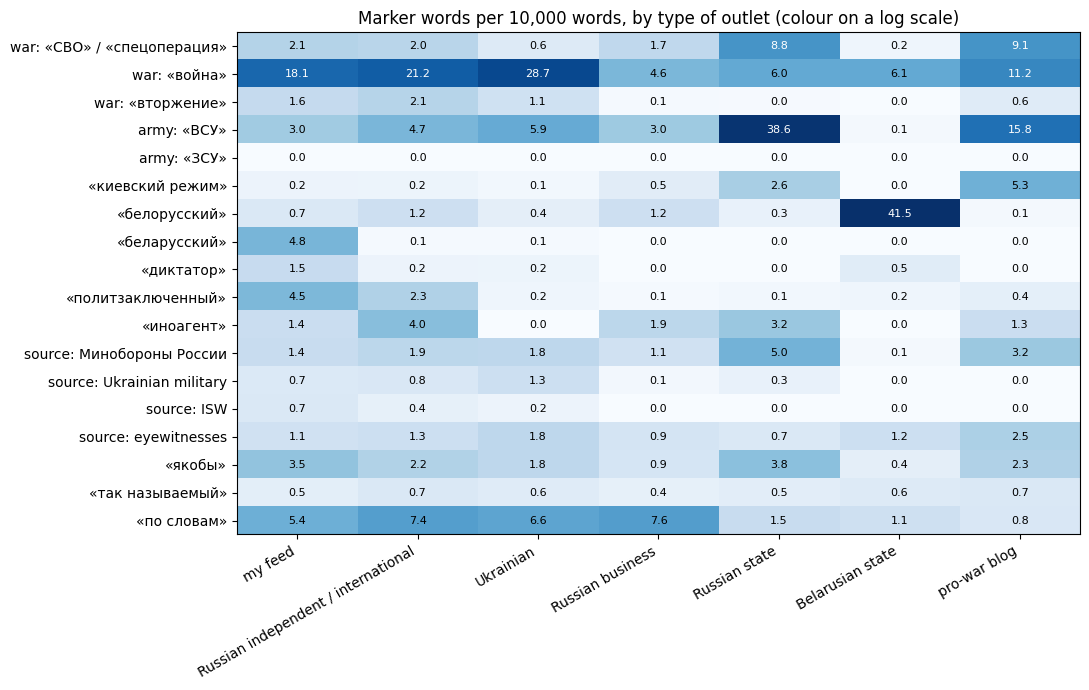

In [75]:
# Outlet types used to group the results (never used for training)
BLOC_BY_CATEGORY = {
    "Russian state": "Russian state",
    "Belarusian state": "Belarusian state",
    "Russian business": "Russian business",
    "Russian independent (exile)": "Russian independent / international",
    "international public broadcaster": "Russian independent / international",
    "Russian pro-war military blog": "pro-war blog",
    "Ukrainian news agency, private": "Ukrainian",
    "Ukrainian general news, private": "Ukrainian",
}
BLOC = {h: ("my feed" if g == "diet" else BLOC_BY_CATEGORY[c])
        for h, g, c in zip(CHANNELS.handle, CHANNELS.group, CHANNELS.category)}
BLOC_ORDER = ["my feed", "Russian independent / international", "Ukrainian", "Russian business",
              "Russian state", "Belarusian state", "pro-war blog"]
df["bloc"] = df.channel.map(BLOC)
txt = df.text_noboiler.str.lower().str.replace("ё", "е", regex=False)

MARKERS = {
    # naming the war and the armies
    "war: «СВО» / «спецоперация»": r"\bсво\b|спецоперац",
    "war: «война»": r"\bвойн(?:а|ы|е|у|ой)\b",
    "war: «вторжение»": r"вторжени",
    "army: «ВСУ»": r"\bвсу\b",
    "army: «ЗСУ»": r"\bзсу\b",
    "«киевский режим»": r"киевск\w* режим",
    # naming Belarus and its politics
    "«белорусский»": r"белорусск",
    "«беларусский»": r"беларусск",
    "«диктатор»": r"диктатор",
    "«политзаключенный»": r"политзаключ",
    "«иноагент»": r"иноагент|иностранн\w* агент",
    # sources
    "source: Минобороны России": r"минобороны (?:россии|рф)",
    "source: Ukrainian military": r"генштаб\w* всу|минобороны украины|воздушн\w* сил\w* (?:всу|украины)",
    "source: ISW": r"\bisw\b|институт\w* изучения войны",
    "source: eyewitnesses": r"очевид",
    # distancing
    "«якобы»": r"\bякобы\b",
    "«так называемый»": r"так называем",
    "«по словам»": r"по словам",
}
# Counts per 10,000 words: my feed's channels post much shorter texts (median 11–41 lemmas for Zerkalo,
# Ateo and NEXTA), so a rate per post would understate their use of every marker.
marker_counts = pd.DataFrame({name: txt.str.count(pat) for name, pat in MARKERS.items()})
words_per_bloc = txt.str.split().str.len().groupby(df.bloc).sum()
marker_table = (marker_counts.groupby(df.bloc).sum().div(words_per_bloc, axis=0) * 10_000).reindex(BLOC_ORDER).T.round(2)
print("marker occurrences per 10,000 words")
display(marker_table)

# Heatmap of marker rates; shading on a log scale so rare and frequent markers are both visible
fig, ax = plt.subplots(figsize=(11, 7))
shown = np.log1p(marker_table.to_numpy())
ax.imshow(shown, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(BLOC_ORDER)))
ax.set_xticklabels(BLOC_ORDER, rotation=30, ha="right")
ax.set_yticks(range(len(marker_table)))
ax.set_yticklabels(marker_table.index)
for i in range(marker_table.shape[0]):
    for j in range(marker_table.shape[1]):
        v = marker_table.iat[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if shown[i, j] > shown.max() * 0.6 else "black")
ax.set_title("Marker words per 10,000 words, by type of outlet (colour on a log scale)")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig6_framing_markers.png", dpi=150, bbox_inches="tight")

### Who acts in strike reports
Strike posts are all posts whose main topic is strike-related, meaning a topic with an attack word among its top 12 lemmas. Within them, a post names the **Russian side as the attacker** if a Russian-side word (российский, Россия, or ВС/армия/войска РФ) stands within one word of an attack word (удар, атака, обстрел, ракета, дрон, беспилотник, БПЛА), in either order. The same rule applies to the **Ukrainian side** (украинский, ВСУ, ЗСУ). An attack word followed by «по» (on) or «на» (at) marks a target, not an attacker, and is not counted. «России» and a bare «РФ» are excluded because they usually name a place («сбили над регионами России», shot down over Russian regions). «В результате удара/атаки» (as a result of a strike) and «прилёт» (a hit) are counted separately as phrasing without an attacker.

**Precision check.** 60 random matches (30 per side) are written to `actor_check.csv`. I read each one and marked whether the side was really named as the attacker; the labelled file gives the rules' precision (1.0 for the Russian side on 28 judgeable matches, 0.9 for the Ukrainian side on 30).

In [76]:
# Strike-related topics: topics with an attack word among their top lemmas
STRIKE_WORDS = {"удар", "атака", "атаковать", "прилет", "сбить", "пво", "поразить", "обстрел", "дрон", "беспилотник"}
STRIKE_TOPICS = [k for k in range(K) if STRIKE_WORDS & set(topic_words[k].split())]
print("strike-related topics:", ", ".join(TOPIC_LABELS.get(k, f"T{k}") for k in STRIKE_TOPICS))

# Attacker rule: a side word within one word of an attack word; "по"/"на" after the attack word marks a target
ATTACK = r"(?:удар\w*|атак\w*|обстрел\w*|ракет\w*|дрон\w*|беспилотник\w*|бпла)"
GAP = r"(?:(?!по\b|на\b)\S+\s+)?"


def actor_pattern(side):
    return rf"\b{side}\s+(?:\S+\s+)?{ATTACK}|\b{ATTACK}\s+{GAP}{side}"


# "России" and a bare "РФ" are usually places ("над регионами России"), so only these forms count as an actor
RU_SIDE = r"(?:российск\w*|россия\b|(?:вс|арми\w*|войск\w*|сил\w*) рф\b)"
UA_SIDE = r"(?:украинск\w*|всу\b|зсу\b)"
# Share of strike posts per outlet type that match each rule
strike = df.topic.isin(STRIKE_TOPICS)
actor = pd.DataFrame({
    "Russian side named as actor": txt[strike].str.contains(actor_pattern(RU_SIDE), regex=True),
    "Ukrainian side named as actor": txt[strike].str.contains(actor_pattern(UA_SIDE), regex=True),
    "«в результате удара/атаки»": txt[strike].str.contains(r"в результате (?:удар|атак|обстрел)\w*", regex=True),
    "«прилет» (no actor)": txt[strike].str.contains(r"\bприлет\w*", regex=True),
})
actor_table = (actor.groupby(df.bloc[strike]).mean() * 100).reindex(BLOC_ORDER).round(1)
actor_table["strike posts"] = df.bloc[strike].value_counts().reindex(BLOC_ORDER)
print("share of strike-topic posts (%), by type of outlet")
display(actor_table)

# Precision check: a random sample of matches to read and mark as correct (1) or not (0)
ACTOR_CHECK = CACHE_DIR / "actor_check.csv"
ACTOR_CHECKED = CACHE_DIR / "actor_check_labeled.csv"
if not ACTOR_CHECK.exists():
    rows_ck = []
    for col in actor.columns[:2]:
        hits = txt[strike][actor[col]]
        for t in hits.sample(min(30, len(hits)), random_state=RNG_SEED):
            rows_ck.append({"rule": col, "text": t[:400].replace("\n", " "), "correct": ""})
    pd.DataFrame(rows_ck).to_csv(ACTOR_CHECK, index=False)
    print(f"wrote {len(rows_ck)} matches to {ACTOR_CHECK} for a precision check")
if ACTOR_CHECKED.exists():
    ck = pd.read_csv(ACTOR_CHECKED)
    ck["correct"] = pd.to_numeric(ck["correct"], errors="coerce")
    print("precision of the actor rules (share of matches read as correct):")
    display(ck.dropna(subset=["correct"]).groupby("rule").correct.agg(["mean", "size"]).round(2))
else:
    print(f"to report precision: mark the 'correct' column in {ACTOR_CHECK.name} with 1 or 0 "
          f"and save it as {ACTOR_CHECKED.name}")

strike-related topics: T0 Strikes on Ukrainian infrastructure, T1 Casualties and accidents, T3 Russian MoD: strikes on Odesa port, T5 Air defence: drones shot down over Russia, T9 Strikes on Kyiv: local reports, T13 Drone and missile attacks
share of strike-topic posts (%), by type of outlet


,Russian side named as actor,Ukrainian side named as actor,«в результате удара/атаки»,«прилет» (no actor),strike posts
bloc,,,,,
my feed,23.1,8.1,5.9,2.5,938
Russian independent / international,39.6,24.8,24.6,1.8,1159
Ukrainian,12.7,3.3,4.6,20.4,1766
Russian business,3.4,12.3,9.7,0.0,349
Russian state,5.0,13.1,3.7,0.1,1708
Belarusian state,0.0,0.4,0.0,0.7,282
pro-war blog,25.0,16.7,2.4,22.6,84


precision of the actor rules (share of matches read as correct):


,mean,size
rule,,
Russian side named as actor,1.0,28
Ukrainian side named as actor,0.9,30


### Fightin' Words: distinctive words, overall and in strike reports

Comparing raw word frequencies between two groups over-ranks rare words. The log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi & Quinn, 2008) shrinks each word's estimate toward its overall frequency and divides by its standard error. For word $w$, groups $a$ and $b$ with counts $y_w^a$, totals $n^a$, and prior pseudo-counts $\alpha_w$ proportional to the word's frequency in the whole corpus ($\alpha_0 = \sum_w \alpha_w$):

$$\delta_w^{(a-b)} = \log \frac{y_w^a + \alpha_w}{n^a + \alpha_0 - y_w^a - \alpha_w} - \log \frac{y_w^b + \alpha_w}{n^b + \alpha_0 - y_w^b - \alpha_w}, \qquad z_w = \frac{\delta_w^{(a-b)}}{\sqrt{\dfrac{1}{y_w^a + \alpha_w} + \dfrac{1}{y_w^b + \alpha_w}}}$$

Words with $|z_w| > 1.96$ are distinctive at roughly the 5% level. Unigrams and bigrams are used, so phrases such as «киевский режим» can appear. The prior strength $\alpha_0 = 500$ pseudo-counts is small next to the group totals (tens of thousands of words), so it stabilizes rare words without swamping the data; with $\alpha_0 = 10{,}000$, no word reached $|z| > 1.3$ in the strike topic.

In [78]:
def fightin_words(texts_a, texts_b, background, alpha0=500, min_df=10, top=15):
    """Log-odds ratio with an informative Dirichlet prior (Monroe et al., 2008); returns the top words per side."""
    # word counts in group A, group B and the whole background corpus
    vec = CountVectorizer(ngram_range=(1, 2), min_df=min_df).fit(background)
    ya = np.asarray(vec.transform(texts_a).sum(axis=0)).ravel()
    yb = np.asarray(vec.transform(texts_b).sum(axis=0)).ravel()
    bg = np.asarray(vec.transform(background).sum(axis=0)).ravel()
    alpha = bg / bg.sum() * alpha0                    # prior proportional to background frequency
    na, nb = ya.sum(), yb.sum()
    delta = (np.log((ya + alpha) / (na + alpha0 - ya - alpha))
             - np.log((yb + alpha) / (nb + alpha0 - yb - alpha)))
    # z-score: delta divided by its approximate standard error (delta method)
    z = delta / np.sqrt(1 / (ya + alpha) + 1 / (yb + alpha))
    vocab = vec.get_feature_names_out()
    order = np.argsort(z)
    return pd.DataFrame({"distinctive of A": vocab[order[::-1][:top]], "z (A)": z[order[::-1][:top]].round(1),
                         "distinctive of B": vocab[order[:top]], "z (B)": z[order[:top]].round(1)})


print("A = my feed, B = all reference outlets (all posts)")
display(fightin_words(df.lem_stripped[df.y == 1], df.lem_stripped[df.y == 0], df.lem_stripped))

strike_lem = df.lem_stripped[strike]
strike_bloc = df.bloc[strike]
print(f"A = my feed, B = all reference outlets (strike-related topics, {strike.sum():,} posts)")
display(fightin_words(strike_lem[strike_bloc == "my feed"], strike_lem[strike_bloc != "my feed"], strike_lem))

state = strike_bloc.isin(["Russian state", "Belarusian state"])
independent = strike_bloc.isin(["Russian independent / international", "Ukrainian", "my feed"])
print("A = Russian and Belarusian state media, B = independent, international and Ukrainian outlets (strike-related topics)")
display(fightin_words(strike_lem[state], strike_lem[independent], strike_lem))

A = my feed, B = all reference outlets (all posts)


,distinctive of A,z (A),distinctive of B,z (B)
0,минск,16.2,сообщить,-14.1
1,беларусский,12.7,всу,-10.5
2,политзаключенный,12.7,отметить,-9.8
3,польша,11.6,сказать,-8.7
4,тихановский,11.2,тыс,-8.7
5,беларусь,11.2,добавить,-7.5
6,рассказывать,10.2,руб,-7.4
7,литва,10.2,владимир путин,-7.1
8,милиция,10.1,владимир,-7.0
9,диктатор,9.8,фото,-6.9


A = my feed, B = all reference outlets (strike-related topics, 6,286 posts)


,distinctive of A,z (A),distinctive of B,z (B)
0,российский,10.4,сообщить,-10.0
1,литва,8.6,всу,-6.7
2,россия ударить,7.8,сообщать,-5.7
3,минск,7.3,минобороны,-5.2
4,нпз,7.3,прилет,-5.0
5,ударить,7.0,регион,-4.8
6,прийтись,6.5,паблик,-4.6
7,час,6.1,мо,-4.2
8,дрон,6.0,сообщить губернатор,-4.0
9,рассказывать,5.9,логистический,-3.9


A = Russian and Belarusian state media, B = independent, international and Ukrainian outlets (strike-related topics)


,distinctive of A,z (A),distinctive of B,z (B)
0,рф,35.9,дрон,-13.6
1,сообщить,27.5,удар,-12.9
2,всу,24.9,российский,-12.0
3,вс,24.3,атаковать,-11.3
4,поразить,24.1,киев,-9.5
5,вс рф,23.1,беспилотник,-9.3
6,бпнуть,20.4,украина,-8.4
7,минобороны,17.3,слово,-8.0
8,мо,14.5,зеленский,-7.3
9,груз,14.3,повредить,-6.7


## 6c. Geography: which places each feed covers

Topics say what a feed covers; places say *where*. Place names are found with named-entity recognition (NER), which was not covered in class: Natasha's `NewsNERTagger`, a neural tagger trained on Russian news, marks spans of text as locations (LOC), people or organizations. Each location span is normalized to dictionary form with pymorphy3 («Харьковскую область» → «харьковский область») and mapped to a region group. Contested territories (Crimea, the occupied parts of Donetsk and Luhansk oblasts) are kept as their own groups instead of being assigned to a country.

A post counts once per region group it mentions. A channel's geographic profile is the share of its location mentions in each group, and the echo score and null model from Section 6 are applied to these profiles in place of topic shares. Location names that are not in the mapping are listed so the mapping can be extended; their share is reported.

In [79]:
# Named-entity recognition with Natasha: location spans in every post
try:
    from natasha import Segmenter, NewsEmbedding, NewsNERTagger, Doc
except ImportError:
    get_ipython().system("pip install -q natasha")
    from natasha import Segmenter, NewsEmbedding, NewsNERTagger, Doc

# Place names are lemmatised with pymorphy3 ("Харьковскую область" -> "харьковский область")
import pymorphy3

_morph = pymorphy3.MorphAnalyzer()


@lru_cache(maxsize=100_000)
def loc_lemma(word):
    return _morph.parse(word.lower())[0].normal_form.replace("ё", "е")


def norm_place(name):
    return " ".join(loc_lemma(t) for t in name.split())


# Run the NER tagger once over all posts and cache the location names
LOC_CACHE = CACHE_DIR / "locations_v1.pkl"
if LOC_CACHE.exists() and CACHED:
    post_locations = pd.read_pickle(LOC_CACHE)
    print(f"loaded locations from {LOC_CACHE}")
else:
    _seg, _ner = Segmenter(), NewsNERTagger(NewsEmbedding())

    def find_locations(text):
        d = Doc(text)
        d.segment(_seg)
        d.tag_ner(_ner)
        return [" ".join(loc_lemma(t.text) for t in s.tokens) for s in d.spans if s.type == "LOC"]

    post_locations = df.text_noboiler.map(find_locations)
    post_locations.to_pickle(LOC_CACHE)

loc_counts = Counter(l for locs in post_locations for l in set(locs))
print(f"{sum(len(l) > 0 for l in post_locations):,} of {len(df):,} posts mention at least one location; "
      f"{len(loc_counts):,} distinct location names")

loaded locations from /content/drive/MyDrive/cs156-news-diet/locations_v1.pkl
26,043 of 32,376 posts mention at least one location; 5,364 distinct location names


In [80]:
# Map location names to 15 region groups; Crimea, the Donbas and the Black Sea are kept as separate groups
REGION_GROUPS = {
    "Ukraine: Kyiv": ["киев", "киевский область", "киевщина", "соломенский район", "голосеевский район",
                      "святошинский район", "оболонский район", "печерский район", "дарницкий район",
                      "деснянский район", "южный мост", "северный мост"],
    "Ukraine: front-line oblasts": ["харьков", "харьковский область", "харьковщина", "запорожье", "запорожский область",
                                    "херсон", "херсонский область", "херсонщина", "сумы", "сумской область",
                                    "сумский область", "днепр", "днепропетровский область", "николаев",
                                    "николаевский область", "краматорск", "славянск", "покровск", "константиновка",
                                    "купянск", "чернигов", "черниговский область", "доброполье", "изюм"],
    "Ukraine: other": ["украина", "одесса", "одесский область", "одесщина", "черноморск", "львов", "львовский область",
                       "винница", "житомир", "полтава", "ровно", "ивано-франковск", "тернополь", "кривой рог",
                       "черкассы", "кировоград", "хмельницкий", "луцк", "ужгород", "закарпатье"],
    "Donbas (Donetsk, Luhansk)": ["донбасс", "донецк", "донецкий область", "днр", "луганск", "луганский область", "лнр",
                                  "мариуполь", "горловка", "макеевка", "лиман", "часов яр", "бахмут", "артемовск", "торецк"],
    "Crimea": ["крым", "севастополь", "керчь", "симферополь"],
    "Black Sea": ["черный море", "азовский море", "керченский пролив"],
    "Russia: Moscow": ["москва", "московский область", "подмосковье", "кремль"],
    "Russia: border regions": ["белгород", "белгородский область", "курск", "курский область", "брянск",
                               "брянский область", "воронеж", "воронежский область", "ростов", "ростовский область",
                               "ростов-на-дону", "таганрог", "краснодар", "краснодарский край", "кубань",
                               "новороссийск", "туапсе"],
    "Russia: other": ["россия", "рф", "российский федерация", "санкт-петербург", "петербург", "ленинградский область",
                      "татарстан", "казань", "екатеринбург", "свердловский область", "новосибирск", "самара",
                      "самарский область", "саратов", "саратовский область", "нижний новгород", "нижегородский область",
                      "чечня", "дагестан", "кабардино-балкария", "ставропольский край", "сочи", "сибирь", "урал",
                      "дальний восток", "владивосток", "камчатка", "иркутск", "иркутский область", "красноярск",
                      "красноярский край", "калининград", "калининградский область", "тверь", "тверской область",
                      "тула", "тульский область", "рязань", "рязанский область", "орел", "орловский область", "липецк",
                      "липецкий область", "смоленск", "смоленский область", "калужский область", "тамбовский область",
                      "пензенский область", "псков", "башкирия", "пермь", "пермский край", "челябинск",
                      "челябинский область", "оренбургский область", "уфа", "волгоград", "волгоградский область",
                      "астраханский область", "ярославль", "ярославский область", "чувашия", "удмуртия", "мордовия",
                      "арктика"],
    "Belarus": ["беларусь", "белоруссия", "республика беларусь", "минск", "гомель", "брест", "гродно", "витебск",
                "могилев", "минский область", "гомельский область", "брестский область", "гродненский область",
                "витебский область", "могилевский область", "жлобин", "бобруйск", "барановичи", "пинск", "борисов"],
    "Poland and the Baltics": ["польша", "варшава", "литва", "вильнюс", "латвия", "рига", "эстония", "таллин",
                               "прибалтика", "балтия", "балтийский море"],
    "USA": ["сша", "америка", "вашингтон", "соединенный штат", "нью-йорк", "белый дом", "флорида", "калифорния", "техас",
            "майами"],
    "EU and Western Europe": ["ес", "евросоюз", "европа", "германия", "фрг", "берлин", "лейпциг", "бонн",
                              "саксонии-анхальт", "мюнхен", "франция", "париж", "великобритания", "британия", "лондон",
                              "италия", "рим", "испания", "нидерланды", "бельгия", "брюссель", "австрия", "вена",
                              "швейцария", "швеция", "финляндия", "норвегия", "дания", "чехия", "венгрия", "словакия",
                              "румыния", "молдавия", "молдова", "болгария", "сербия", "греция"],
    "Middle East": ["израиль", "иран", "газа", "сектор газа", "тегеран", "ливан", "сирия", "ирак", "саудовский аравия",
                    "оаэ", "дубай", "катар", "турция", "анкара", "стамбул", "иордания", "египет", "йемен", "тель-авив",
                    "ближний восток", "ормузский пролив", "персидский залив"],
    "Asia and other": ["китай", "кнр", "пекин", "япония", "индия", "нью-дели", "кндр", "северный корея", "южный корея",
                       "корея", "казахстан", "узбекистан", "киргизия", "кыргызстан", "бишкек", "таджикистан", "армения",
                       "ереван", "азербайджан", "грузия", "венесуэла", "бразилия", "канада", "африка", "монголия",
                       "вьетнам", "тайвань", "пакистан", "афганистан", "непал", "таиланд", "индонезия", "азия"],
}
# Tagged as locations but not places in the sense used here: "the West" as a political bloc, and the USSR
NOT_PLACES = {"запад", "ссср"}

LOC_TO_GROUP = {name: group for group, names in REGION_GROUPS.items() for name in names}
GROUPS = list(REGION_GROUPS)

place_counts = Counter({l: c for l, c in loc_counts.items() if l not in NOT_PLACES})
unmapped = Counter({l: c for l, c in place_counts.items() if l not in LOC_TO_GROUP})
share_mapped = 1 - sum(unmapped.values()) / max(sum(place_counts.values()), 1)
print(f"mapped: {share_mapped:.0%} of location mentions (excluding {', '.join(sorted(NOT_PLACES))}). "
      "Most frequent unmapped names (add them to REGION_GROUPS if they belong to a group):")
print(", ".join(f"{l} ({c})" for l, c in unmapped.most_common(40)))

# Region profile of each post: each region group it mentions counts once, shares sum to 1
post_groups = post_locations.map(lambda locs: sorted({LOC_TO_GROUP[l] for l in locs if l in LOC_TO_GROUP}))
has_loc = post_groups.str.len() > 0
G = np.zeros((len(df), len(GROUPS)))
for i, gs in enumerate(post_groups):
    for g in gs:
        G[i, GROUPS.index(g)] = 1.0
G = G / np.maximum(G.sum(axis=1, keepdims=True), 1)

mapped: 74% of location mentions (excluding запад, ссср). Most frequent unmapped names (add them to REGION_GROUPS if they belong to a group):
соединить штат (84), сума (68), красный море (68), абу-даби (68), гренландия (68), московский регион (67), оман (66), дождь (66), бурятия (65), сумах (64), ирландия (64), павлоград (60), якутия (59), борисполь (59), токио (58), куба (58), шпицберген (57), земля (55), буча (54), днепровский район (53), запорожский (52), ульяновск (52), ульяновский область (50), стерлитамак (50), аргентина (49), каспийский море (49), сеул (49), подольский район (48), австралия (47), теннесси (47), люксембург (45), анкоридж (45), ягодин (45), белград (44), северный ирландия (44), амурский область (43), житомирский область (43), белгородский (42), шевченковский район (42), европейский союз (42)


geographic echo score 0.0098; equal-weight feed narrower than 17% of 4-channel feeds


,my feed,basket,log gap
Ukraine: front-line oblasts,0.012,0.027,-0.801
Russia: border regions,0.018,0.024,-0.297
Black Sea,0.003,0.004,-0.238
Crimea,0.005,0.006,-0.219
Ukraine: Kyiv,0.050,0.062,-0.207
Russia: Moscow,0.060,0.072,-0.181
Ukraine: other,0.100,0.117,-0.155
Russia: other,0.246,0.275,-0.109
"Donbas (Donetsk, Luhansk)",0.011,0.011,-0.032
Asia and other,0.068,0.063,0.076


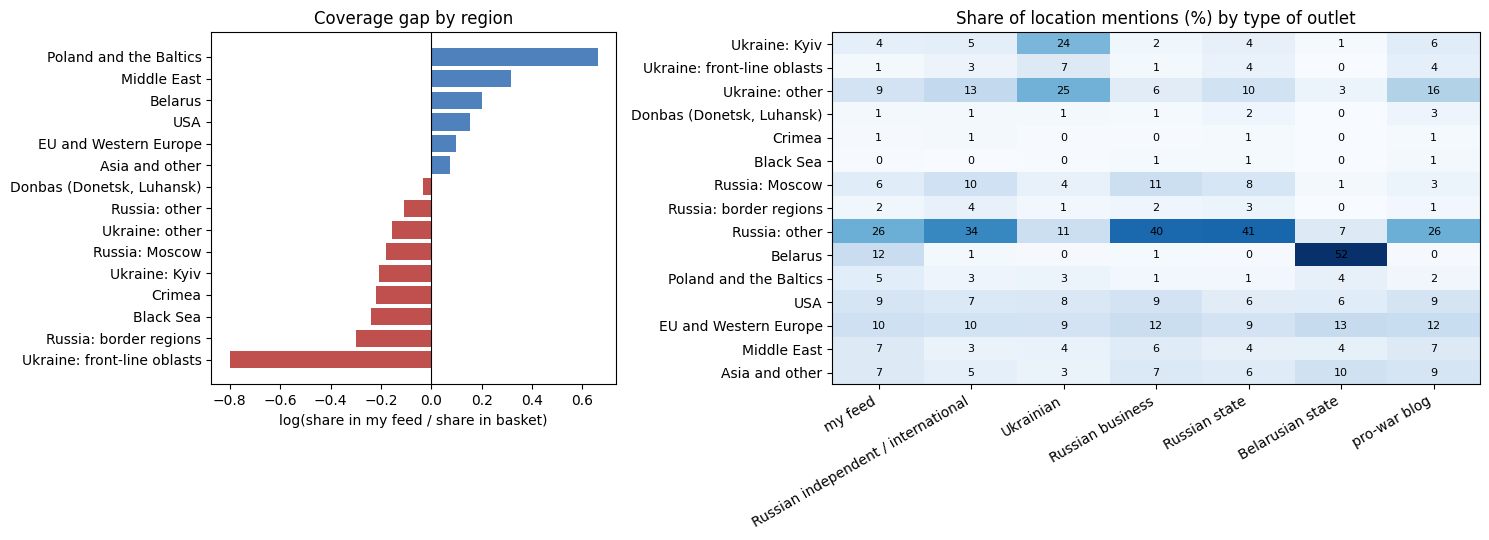

In [81]:
# Geographic echo score and coverage gap, using the same method as for topics
geo_s = (pd.DataFrame(G[has_loc.to_numpy()], index=df.channel[has_loc].values, columns=GROUPS)
           .groupby(level=0).mean().reindex(ALL_CHANNELS))
p_geo = geo_s.mean(axis=0)
q_geo = w @ geo_s.loc[DIET].to_numpy()
geo_gap = pd.DataFrame({"my feed": q_geo, "basket": p_geo.to_numpy(),
                        "log gap": np.log((q_geo + 1e-6) / (p_geo.to_numpy() + 1e-6))}, index=GROUPS).sort_values("log gap")
echo_geo = jsd(q_geo, p_geo.to_numpy())
geo_combos = jsd(geo_s.to_numpy()[_combos4].mean(axis=1), p_geo.to_numpy()[None, :])
pct_geo = (geo_combos < jsd(geo_s.loc[DIET].mean(axis=0).to_numpy(), p_geo.to_numpy())).mean() * 100
print(f"geographic echo score {echo_geo:.4f}; equal-weight feed narrower than {pct_geo:.0f}% of 4-channel feeds")
display(geo_gap.round(3))

geo_bloc = (pd.DataFrame(G[has_loc.to_numpy()], columns=GROUPS).groupby(df.bloc[has_loc].values).mean()
              .reindex(BLOC_ORDER) * 100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.6]})
axes[0].barh(geo_gap.index, geo_gap["log gap"], color=np.where(geo_gap["log gap"] < 0, "#c0504d", "#4f81bd"))
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set_xlabel("log(share in my feed / share in basket)")
axes[0].set_title("Coverage gap by region")
im = axes[1].imshow(geo_bloc.T.to_numpy(), cmap="Blues", aspect="auto")
axes[1].set_xticks(range(len(BLOC_ORDER)))
axes[1].set_xticklabels(BLOC_ORDER, rotation=30, ha="right")
axes[1].set_yticks(range(len(GROUPS)))
axes[1].set_yticklabels(GROUPS)
for i in range(len(GROUPS)):
    for j in range(len(BLOC_ORDER)):
        v = geo_bloc.iat[j, i]
        axes[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                     color="white" if v > 0.55 * np.nanmax(geo_bloc.to_numpy()) else "black")
axes[1].set_title("Share of location mentions (%) by type of outlet")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_geography.png", dpi=150, bbox_inches="tight")

In [84]:
# Reading-weight sensitivity for the geographic profile (same 2,000 random weightings as in Section 6)
geo_D = geo_s.loc[DIET].to_numpy()
echo_geo_w = jsd(W_DRAWS @ geo_D, p_geo.to_numpy()[None, :])
pct_geo_w = (geo_combos[None, :] < echo_geo_w[:, None]).mean(axis=1) * 100
print(f"geographic echo over 2,000 random weightings: median {np.median(echo_geo_w):.4f}, "
      f"90% of draws in [{np.percentile(echo_geo_w, 5):.4f}, {np.percentile(echo_geo_w, 95):.4f}]; "
      f"percentile among 4-channel feeds: median {np.median(pct_geo_w):.0f}%, "
      f"90% in [{np.percentile(pct_geo_w, 5):.0f}%, {np.percentile(pct_geo_w, 95):.0f}%]")

geographic echo over 2,000 random weightings: median 0.0180, 90% of draws in [0.0072, 0.0670]; percentile among 4-channel feeds: median 32%, 90% in [10%, 98%]


## 7. Interactive selector
Choose any combination of channels and see its topic and geographic echo scores, where it falls among all feeds of the same size, and its coverage gap for every topic. The buttons reset the selection to my feed, to all channels, or to none. The same tool is available as a standalone web dashboard (Section 9 exports its data).

In [85]:
# Interactive selector: tick channels to see their echo scores, percentile and topic gaps
try:
    import ipywidgets as widgets
    if IN_COLAB:
        from google.colab import output
        output.enable_custom_widget_manager()

    boxes = {h: widgets.Checkbox(value=h in DIET, description=n, indent=False)
             for h, n in zip(CHANNELS.handle, CHANNELS.name)}
    out = widgets.Output()
    has_geo = "geo_s" in globals()

    def update(_=None):
        sel = [h for h, b in boxes.items() if b.value]
        with out:
            out.clear_output(wait=True)
            if not sel:
                print("Select at least one channel.")
                return
            q = theta_s.loc[sel].mean(axis=0).to_numpy()
            e = jsd(q, p_R)
            pc = (null[len(sel)] < e).mean() * 100
            line = f"{len(sel)} channels | topic echo {e:.4f}, narrower than {pc:.0f}% of {len(sel)}-channel feeds"
            if has_geo:
                eg = jsd(geo_s.loc[sel].fillna(0).mean(axis=0).to_numpy(), p_geo.to_numpy())
                line += f" | geographic echo {eg:.4f}"
            print(line)

            g = pd.Series(np.log((q + 1e-9) / p_R), index=theta_s.columns).sort_values()
            fig, axes = plt.subplots(1, 2, figsize=(13, 0.32 * K + 1.5), gridspec_kw={"width_ratios": [1.6, 1]})
            axes[0].barh(g.index, g.values, color=np.where(g.values < 0, "#c0504d", "#4f81bd"))
            axes[0].axvline(0, color="k", lw=0.8)
            axes[0].set_xlim(min(-2, g.min() - 0.2), max(2, g.max() + 0.2))
            axes[0].set_xlabel("log(share in selected feed / share in basket)")
            axes[0].set_title("Coverage gap by topic (red: covered less than the basket)")
            axes[1].hist(null[len(sel)], bins=40, color="0.75")
            axes[1].axvline(e, color="#c0504d", lw=2, label="selected feed")
            axes[1].set_xlabel(f"topic echo score, all {len(null[len(sel)]):,} {len(sel)}-channel feeds")
            axes[1].set_yticks([])
            axes[1].legend(frameon=False)
            axes[1].set_title("Where this feed falls")
            fig.tight_layout()
            plt.show()

    def preset(handles):
        def apply(_):
            for h, b in boxes.items():
                b.unobserve(update, "value")
                b.value = h in handles
                b.observe(update, "value")
            update()
        return apply

    buttons = []
    for label, handles in (("My feed", set(DIET)), ("All channels", set(CHANNELS.handle)), ("Clear", set())):
        btn = widgets.Button(description=label)
        btn.on_click(preset(handles))
        buttons.append(btn)

    for b in boxes.values():
        b.observe(update, "value")
    display(widgets.VBox([widgets.HBox(buttons),
                          widgets.GridBox(list(boxes.values()),
                                          layout=widgets.Layout(grid_template_columns="repeat(3, 220px)")),
                          out]))
    update()
except ImportError:
    print("pip install ipywidgets to use the selector")

## 8. Codebook labels: comparing hand-defined categories with the topic model

The topic model decides for itself what the categories are. This section checks the results against categories I defined myself:

1. **Codebook.** 14 categories with written rules for borderline cases.
2. **Sample.** 400 posts, stratified by topic and by my feed versus the basket, shuffled and shown without the channel name, so the source cannot influence the label.
3. **Labels.** I labelled 200 posts by hand (`codebook_label`). A large language model (Claude, Anthropic) labelled all 400 from the same codebook and rules without seeing my labels (`llm_label`). Agreement on the shared 200 posts is measured with Cohen's kappa; the rule set in advance was to train on the 400 LLM labels only if kappa ≥ 0.6.
4. **Codebook classifier.** Logistic regression on TF-IDF learns the codebook from the labelled posts (5-fold cross-validation) and labels the full corpus.
5. **Comparison.** Adjusted Rand index and a cross-table between codebook labels and topics, and the echo score recomputed from codebook categories.

The sample is written to `label_sample.csv`; the labelled version is read from `label_sample_labeled.csv`.

In [92]:
# The codebook and the stratified sample of 400 posts (written once to Drive)
CODEBOOK = {
    1: "War: strikes and casualties",
    2: "War: front line and military operations",
    3: "War: diplomacy and international reaction",
    4: "Ukraine: domestic politics and society",
    5: "Russia: politics, government and elections",
    6: "Russia: repression, courts and censorship",
    7: "Russia: economy and business",
    8: "Belarus: state agenda (Lukashenko, officials)",
    9: "Belarus: repression and political prisoners",
    10: "Belarus: society and other",
    11: "USA, EU and international politics",
    12: "Accidents, crime and incidents (not war)",
    13: "Culture, sport and lifestyle",
    14: "Other",
}
SAMPLE_PATH = CACHE_DIR / "label_sample.csv"
LABELED_PATH = CACHE_DIR / "label_sample_labeled.csv"
N_SAMPLE = 400

if not SAMPLE_PATH.exists():
    per_cell = int(np.ceil(N_SAMPLE / (K * 2)))
    picked = (df.groupby(["topic", "y"], group_keys=False)
                .apply(lambda g: g.sample(min(len(g), per_cell), random_state=RNG_SEED)))
    picked = picked.sample(frac=1, random_state=RNG_SEED).head(N_SAMPLE)
    out = pd.DataFrame({"row": picked.index, "text": picked.text_noboiler.str.slice(0, 700),
                        "codebook_label": "", "llm_label": ""})
    out.to_csv(SAMPLE_PATH, index=False)
    print(f"wrote {len(out)} posts to {SAMPLE_PATH}")
else:
    print(f"{SAMPLE_PATH} already exists (delete it to draw a new sample)")
print("\n".join(f"{k:>2}  {v}" for k, v in CODEBOOK.items()))

/content/drive/MyDrive/cs156-news-diet/label_sample.csv already exists (delete it to draw a new sample)
 1  War: strikes and casualties
 2  War: front line and military operations
 3  War: diplomacy and international reaction
 4  Ukraine: domestic politics and society
 5  Russia: politics, government and elections
 6  Russia: repression, courts and censorship
 7  Russia: economy and business
 8  Belarus: state agenda (Lukashenko, officials)
 9  Belarus: repression and political prisoners
10  Belarus: society and other
11  USA, EU and international politics
12  Accidents, crime and incidents (not war)
13  Culture, sport and lifestyle
14  Other


**How the LLM labels were produced.** The 400 posts were given to the model in a chat session together with the codebook and the same written rules I used, with no channel names and without my labels. Its labels were saved to the `llm_label` column of `label_sample_labeled.csv`, so the analysis below can be rerun without the model.

In [100]:
from sklearn.metrics import cohen_kappa_score, classification_report

# Train on the LLM labels (400 posts) because agreement with my labels is kappa >= 0.6;
# set to "codebook_label" to train on my 200 labels instead
LABEL_SOURCE = "llm_label"

if LABELED_PATH.exists():
    lab = pd.read_csv(LABELED_PATH)
    lab["codebook_label"] = pd.to_numeric(lab["codebook_label"], errors="coerce")
    lab["llm_label"] = pd.to_numeric(lab["llm_label"], errors="coerce") if "llm_label" in lab else np.nan
    both = lab.dropna(subset=["codebook_label", "llm_label"])
    if len(both) >= 30:
        kappa = cohen_kappa_score(both.codebook_label.astype(int), both.llm_label.astype(int))
        print(f"agreement between my labels and the LLM's on {len(both)} posts: Cohen's kappa = {kappa:.2f}")

    # Codebook classifier: logistic regression on TF-IDF, 5-fold cross-validated
    train = lab.dropna(subset=[LABEL_SOURCE]).copy()
    train["label"] = train[LABEL_SOURCE].astype(int)
    rare = train.label.value_counts()[lambda s: s < 5].index      # too few examples to learn: merged into Other
    train.loc[train.label.isin(rare), "label"] = 14
    X_lab = df.loc[train.row, "lem_stripped"].to_numpy()
    code_clf = Pipeline([("tfidf", TfidfVectorizer(min_df=2, sublinear_tf=True)),
                         ("clf", LogisticRegression(class_weight="balanced", max_iter=3000))])
    n_splits = int(min(5, train.label.value_counts().min()))
    pred = cross_val_predict(code_clf, X_lab, train.label, cv=StratifiedKFold(n_splits, shuffle=True, random_state=RNG_SEED))
    print(f"codebook classifier, {n_splits}-fold cross-validation on {len(train)} labeled posts: "
          f"accuracy {accuracy_score(train.label, pred):.3f}, macro-F1 {f1_score(train.label, pred, average='macro'):.3f}")
    print(classification_report(train.label, pred, target_names=[CODEBOOK[c] for c in sorted(train.label.unique())],
                                zero_division=0))

    # Label the full corpus and compare the labels with the topic model
    code_clf.fit(X_lab, train.label)
    df["code_label"] = code_clf.predict(df.lem_stripped)
    print(f"adjusted Rand index, codebook labels vs topic-model topics: {adjusted_rand_score(df.code_label, df.topic):.2f}")
    xtab = pd.crosstab(df.code_label.map(CODEBOOK), df.topic.map(lambda k: f"T{k}"), normalize="index").round(2)
    display(xtab)

    e_code, pct_code = echo_and_percentile(pd.get_dummies(df.code_label).astype(float).to_numpy())
    print(f"echo score from codebook labels: {e_code:.4f}; equal-weight feed narrower than {pct_code:.0f}% of 4-channel feeds")
else:
    print(f"no labeled file yet: label {SAMPLE_PATH.name} and save it as {LABELED_PATH.name} to run this section")

agreement between my labels and the LLM's on 200 posts: Cohen's kappa = 0.90
codebook classifier, 5-fold cross-validation on 400 labeled posts: accuracy 0.593, macro-F1 0.464
                                               precision    recall  f1-score   support

                  War: strikes and casualties       0.69      0.87      0.77        76
      War: front line and military operations       0.62      0.40      0.49        25
    War: diplomacy and international reaction       0.64      0.72      0.68        82
       Ukraine: domestic politics and society       0.58      0.50      0.54        14
   Russia: politics, government and elections       0.66      0.63      0.64        30
    Russia: repression, courts and censorship       1.00      0.09      0.17        11
                 Russia: economy and business       0.38      0.20      0.26        15
Belarus: state agenda (Lukashenko, officials)       0.67      0.44      0.53         9
                   Belarus: society and o

topic,T0,T1,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T2,T3,T4,T5,T6,T7,T8,T9
code_label,,,,,,,,,,,,,,,,,,,,
"Accidents, crime and incidents (not war)",0.00,0.20,0.01,0.20,0.02,0.02,0.12,0.00,0.05,0.00,0.01,0.01,0.01,0.01,0.00,0.01,0.00,0.29,0.01,0.02
Belarus: society and other,0.00,0.02,0.02,0.01,0.48,0.01,0.25,0.01,0.02,0.00,0.03,0.01,0.01,0.01,0.01,0.01,0.00,0.07,0.01,0.01
"Belarus: state agenda (Lukashenko, officials)",0.00,0.01,0.01,0.00,0.71,0.00,0.15,0.01,0.01,0.01,0.01,0.01,0.00,0.00,0.00,0.00,0.01,0.03,0.04,0.00
"Culture, sport and lifestyle",0.00,0.01,0.05,0.01,0.07,0.02,0.44,0.04,0.03,0.01,0.01,0.04,0.01,0.01,0.01,0.01,0.01,0.19,0.03,0.01
Other,0.00,0.02,0.05,0.02,0.06,0.01,0.52,0.01,0.05,0.01,0.03,0.02,0.01,0.01,0.02,0.02,0.01,0.09,0.02,0.02
Russia: economy and business,0.00,0.00,0.03,0.02,0.01,0.01,0.37,0.01,0.01,0.00,0.29,0.03,0.00,0.04,0.00,0.00,0.00,0.01,0.16,0.01
"Russia: politics, government and elections",0.00,0.01,0.03,0.01,0.01,0.00,0.18,0.01,0.02,0.01,0.00,0.03,0.45,0.01,0.01,0.00,0.00,0.09,0.12,0.00
"Russia: repression, courts and censorship",0.00,0.00,0.01,0.00,0.01,0.00,0.14,0.01,0.01,0.00,0.01,0.01,0.02,0.03,0.00,0.00,0.00,0.73,0.00,0.00
"USA, EU and international politics",0.00,0.01,0.03,0.03,0.04,0.01,0.22,0.06,0.01,0.01,0.12,0.09,0.02,0.01,0.00,0.01,0.22,0.08,0.04,0.01


echo score from codebook labels: 0.0148; equal-weight feed narrower than 9% of 4-channel feeds


## 9. Export for the dashboard
Writes the channel-level profiles (topic mixes, region shares, labels and reading weights) to `profiles.json` in the Drive folder. The standalone dashboard recomputes the echo scores, percentiles and gaps from this file in the browser. No individual posts are exported.

In [ ]:
# Export channel profiles for the web dashboard
_bloc = df.groupby("channel").bloc.first()
_name = CHANNELS.set_index("handle").name
_weight = CHANNELS.set_index("handle").weight

profiles = {
    "meta": {"demo": False, "title": "What My News Diet Leaves Out",
             "window": "1 September – 4 October 2026", "n_posts": int(len(df))},
    "channels": [{"handle": h, "name": str(_name[h]),
                  "group": "My feed" if h in DIET else str(_bloc.get(h, "Other")),
                  "weight": float(_weight[h]) if h in DIET else None} for h in ALL_CHANNELS],
    "topics": [TOPIC_LABELS[k] for k in range(K)],
    "regions": list(GROUPS),
    "theta": theta_s.loc[ALL_CHANNELS].to_numpy().round(6).tolist(),
    "geo": geo_s.loc[ALL_CHANNELS].fillna(0).to_numpy().round(6).tolist(),
}
with open(CACHE_DIR / "profiles.json", "w", encoding="utf-8") as f:
    json.dump(profiles, f, ensure_ascii=False, indent=1)
print(f"wrote {CACHE_DIR / 'profiles.json'}: {len(profiles['channels'])} channels, "
      f"{len(profiles['topics'])} topics, {len(profiles['regions'])} region groups")